# Project B03 - Kepadatan Lalu Lintas Berdasarkan Waktu dan Lokasi
**Mata kuliah:** Pembelajaran Mesin

**Kelompok:** Delapan (VIII)


**Anggota:**
1. Daniel Pangihutan Siregar (231112256)
2. Arisanti Nurlaili (231112294)
3. Maria Hana Gultom (231112124)

**Dataset:** Enriched Traffic Datasets for Madrid (subset) | **Metode:** Clustering (classical machine learning)

| Bagian | Isi | Komponen UTS |
|---|---|---|
| 1-3 | Identitas proyek, rumusan masalah, dataset dan sumber | A, B |
| 4-6 | Data understanding, EDA, kualitas data | B, C |
| 7-10 | Preprocessing, feature engineering, pipeline awal | D, E |
| 11-20 | Desain evaluasi dan pembagian data, modeling clustering (K-Means, fitur, algoritma alternatif, PCA, kestabilan, profil cluster) | D, F, G |
| 21-25 | Baseline dan model kandidat (hold-out), kestabilan, tabel hasil, ablasi fitur, catatan eksperimen | F, G, H |
| 26-29 | Instruksi reproduksi, rencana pasca-UTS, ringkasan hasil, referensi | I |

## 1. Project Identification
| Item | Keterangan |
|---|---|
| Project ID | **B03** |
| Topik project | Kepadatan Lalu Lintas Berdasarkan Waktu dan Lokasi |
| Fokus / metode analisis | Clustering (Unsupervised Learning, Classical Machine Learning) |
| Unit analisis | Satu observasi = satu sensor lalu lintas pada satu jam pengukuran |
| Target/variabel yang dianalisis | Tidak ada target (unsupervised). Dianalisis: `traffic_intensity` (indikator kepadatan) dalam konteks waktu (`date`, `day_type`), lokasi (`id`, koordinat, karakter jalan) |

## 2. Problem Formulation
- **Masalah:** tipe kondisi lalu lintas di Madrid menurut waktu dan lokasi belum diketahui; data tidak memiliki label kepadatan.
- **Alasan penting:** pengelola lalu lintas perlu mengetahui kapan dan di ruas mana lalu lintas tinggi, sedang, atau rendah untuk pengaturan sinyal, pemeliharaan, dan informasi pengguna jalan.
- **Tujuan:** mengelompokkan kondisi lalu lintas (sensor x jam) berdasarkan waktu dan lokasi, lalu menafsirkan profil tiap cluster.
- **Target/keluaran:** tidak ada variabel target (unsupervised). Keluaran: label cluster, profil cluster, dan penilaian kualitas, kestabilan, serta generalisasi pada periode yang tidak dipakai melatih.
- **Pendekatan:** clustering klasik (K-Means; pembanding Gaussian Mixture, Hierarchical Ward, DBSCAN). Tanpa deep learning.
- **Batasan:** satu kota dan satu subset (300 sensor, Juni 2022 sampai Oktober 2023); kepadatan diukur dengan `traffic_intensity` (volume kendaraan per interval, bukan kendaraan per kilometer); tidak memprediksi masa depan; hanya machine learning klasik.

## 3. Dataset dan Sumber
| Informasi | Keterangan |
|---|---|
| Nama dataset | Enriched Traffic Datasets for Madrid (Madrid Traffic Dataset, MTD), Version 4, subset |
| Sumber | Mendeley Data. Data asli dari Madrid Open Data Portal; atribut jalan dari OpenStreetMap. Penulis: Iván Gómez dan Sergio Ilarri |
| Link sumber | https://data.mendeley.com/datasets/697ht4f65b (DOI: 10.17632/697ht4f65b.4) |
| Unit observasi | Satu sensor lalu lintas pada satu jam (sensor x jam) |
| Jumlah baris | 3.699.308 (subset penuh) |
| Jumlah kolom | 17 |
| Variabel utama | `id`, `date`, `traffic_intensity`, `day_type`, `latitude`, `longitude`, `highway`, `lanes`, `maxspeed` |
| Target, jika ada | Tidak ada (clustering) |
| Jenis data | Numerik, kategorikal, waktu (datetime), dan geospasial |
| Lisensi/keterangan penggunaan | (isi dari halaman Mendeley) |

**Subset:** 300 sensor, Juni 2022 sampai Oktober 2023 (di versi penuh: 554 sensor, 30 bulan). Subset dipilih karena keterbatasan komputasi (versi penuh sekitar 10 GB).

**Catatan:** Menurut penulis, data sudah melalui pembersihan (outlier, duplikat, sensor kurang aktif) dan sebagian pemrosesan untuk pemodelan prediksi.

## Setup dan Load Data

In [2]:
import os, pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 50)
sns.set_theme(style='whitegrid'); os.makedirs('figs', exist_ok=True)

try:
    from google.colab import drive
    drive.mount('/content/drive')
    PATH = '/content/drive/MyDrive/Project_Kelompok8_B03/MTD_complete_data.csv'
except ImportError:
    PATH = 'sample.csv'

df = pd.read_csv(PATH, parse_dates=['date'])

# Batas pembagian data waktu: latih = date < CUTOFF, uji = date >= CUTOFF (lihat bagian 11)
CUTOFF = pd.Timestamp('2023-07-01')
df.head()

Mounted at /content/drive


,id,date,longitude,latitude,traffic_intensity,day_type,wind,temperature,precipitation,original_point,closest_point,oneway,lanes,name,highway,maxspeed,length
0,3397,2022-06-01 00:00:00,-3.713882,40.439016,192.500000,Working day,0.9,9.5,0.0,POINT (-3.71388213805252 40.43901616364479),POINT (-3.7140062 40.4390111),True,2.0,Calle de Cea Bermúdez,tertiary,50.0,106.085
1,3397,2022-06-01 01:00:00,-3.713882,40.439016,112.500000,Working day,0.9,9.5,0.0,POINT (-3.71388213805252 40.43901616364479),POINT (-3.7140062 40.4390111),True,2.0,Calle de Cea Bermúdez,tertiary,50.0,106.085
2,3397,2022-06-01 02:00:00,-3.713882,40.439016,74.500000,Working day,0.9,9.5,0.0,POINT (-3.71388213805252 40.43901616364479),POINT (-3.7140062 40.4390111),True,2.0,Calle de Cea Bermúdez,tertiary,50.0,106.085
3,3397,2022-06-01 03:00:00,-3.713882,40.439016,62.333333,Working day,0.9,9.5,0.0,POINT (-3.71388213805252 40.43901616364479),POINT (-3.7140062 40.4390111),True,2.0,Calle de Cea Bermúdez,tertiary,50.0,106.085
4,3397,2022-06-01 04:00:00,-3.713882,40.439016,80.750000,Working day,0.9,9.5,0.0,POINT (-3.71388213805252 40.43901616364479),POINT (-3.7140062 40.4390111),True,2.0,Calle de Cea Bermúdez,tertiary,50.0,106.085


## 4. Data Understanding
### 4.1 Struktur data

In [3]:
print('Jumlah baris:', df.shape[0], '| Jumlah kolom:', df.shape[1])
df.info()

Jumlah baris: 3699308 | Jumlah kolom: 17
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3699308 entries, 0 to 3699307
Data columns (total 17 columns):
 #   Column             Dtype         
---  ------             -----         
 0   id                 int64         
 1   date               datetime64[ns]
 2   longitude          float64       
 3   latitude           float64       
 4   traffic_intensity  float64       
 5   day_type           object        
 6   wind               float64       
 7   temperature        float64       
 8   precipitation      float64       
 9   original_point     object        
 10  closest_point      object        
 11  oneway             bool          
 12  lanes              float64       
 13  name               object        
 14  highway            object        
 15  maxspeed           float64       
 16  length             float64       
dtypes: bool(1), datetime64[ns](1), float64(9), int64(1), object(5)
memory usage: 455.1+ MB


In [4]:
df.sample(5, random_state=42)

,id,date,longitude,latitude,traffic_intensity,day_type,wind,temperature,precipitation,original_point,closest_point,oneway,lanes,name,highway,maxspeed,length
3595959,5512,2023-10-23 11:00:00,-3.690183,40.456615,1694.25,Working day,1.41,3.2,0.0,POINT (-3.69018270632836 40.45661487194624),POINT (-3.6901836 40.4565898),True,3.0,Paseo de la Castellana,primary,50.0,234.124
2619114,3654,2023-06-04 22:00:00,-3.688720,40.411896,688.75,Sunday,1.97,5.9,5.5,POINT (-3.68872049451866 40.41189580803501),POINT (-3.6887095 40.4120933),True,2.0,Calle de Alfonso XII,tertiary,50.0,289.143
1674530,6019,2023-01-23 14:00:00,-3.650815,40.448731,1008.75,Working day,1.41,3.2,0.0,POINT (-3.65081502074129 40.44873061233285),POINT (-3.6507358 40.4486218),True,3.0,Calle de Arturo Soria,primary,50.0,100.204
1699675,6496,2023-01-19 02:00:00,-3.626931,40.415742,90.75,Working day,0.94,5.1,0.0,POINT (-3.62693104185572 40.41574217378351),POINT (-3.62675 40.4157058),True,3.0,Calle de la Fuente Carrantona,primary,50.0,350.006
789269,5849,2022-09-15 10:00:00,-3.634976,40.386303,599.00,Working day,0.83,2.2,0.0,POINT (-3.63497646781135 40.38630273234619),POINT (-3.6345632 40.3857216),True,3.0,M-40,motorway,100.0,443.527


In [5]:
num_cols = ['longitude','latitude','traffic_intensity','wind','temperature','precipitation','lanes','maxspeed','length']
cat_cols = ['day_type','highway','name','oneway','id']
print('Numerik     :', num_cols)
print('Kategorikal :', cat_cols, '(id bertipe angka tetapi berfungsi sebagai kode sensor)')
print('Geometri WKT:', ['original_point','closest_point'])
print('Waktu       : date |', df['date'].min(), 's.d.', df['date'].max())
print('Sensor unik :', df['id'].nunique())

Numerik     : ['longitude', 'latitude', 'traffic_intensity', 'wind', 'temperature', 'precipitation', 'lanes', 'maxspeed', 'length']
Kategorikal : ['day_type', 'highway', 'name', 'oneway', 'id'] (id bertipe angka tetapi berfungsi sebagai kode sensor)
Geometri WKT: ['original_point', 'closest_point']
Waktu       : date | 2022-06-01 00:00:00 s.d. 2023-10-31 23:00:00
Sensor unik : 300


### 4.2 Deskripsi fitur dan unit observasi
**Unit observasi:** satu sensor lalu lintas pada satu jam. **Jumlah observasi:** 3.699.308. **Jumlah fitur:** 17 kolom.
| Variabel | Tipe | Keterangan |
|---|---|---|
| `id` | int | Kode sensor lalu lintas (300 sensor unik); kategori, bukan ukuran |
| `date` | datetime | Waktu pengukuran (per jam) |
| `longitude`, `latitude` | float | Koordinat sensor |
| `traffic_intensity` | float | Jumlah kendaraan per interval (indikator kepadatan) |
| `day_type` | string | Kelas hari: Working day, Sunday, Holiday, Saturday |
| `wind`, `temperature`, `precipitation` | float | Variabel cuaca pada waktu pengukuran (satuan tidak dilaporkan; tampak sudah diolah penulis) |
| `original_point`, `closest_point` | string (WKT) | Titik asli sensor dan titik terdekat pada jaringan jalan |
| `oneway` | bool | Ruas jalan satu arah atau tidak |
| `lanes` | float | Jumlah lajur ruas jalan |
| `name` | string | Nama ruas jalan |
| `highway` | string | Kelas jalan OpenStreetMap (11 kategori) |
| `maxspeed` | float | Batas kecepatan maksimum (km/jam) |
| `length` | float | Panjang ruas jalan (meter) |
**Target:** tidak ada (unsupervised).

### 4.3 Statistik dasar numerik

In [6]:
d = df[num_cols].describe().T
d['median']=df[num_cols].median(); d['Q1']=df[num_cols].quantile(.25); d['Q3']=df[num_cols].quantile(.75); d['IQR']=d['Q3']-d['Q1']
d[['mean','median','std','min','max','Q1','Q3','IQR']].round(3)

,mean,median,std,min,max,Q1,Q3,IQR
longitude,-3.684,-3.691,0.037,-3.833,-3.584,-3.707,-3.663,0.044
latitude,40.428,40.428,0.034,40.350,40.506,40.406,40.455,0.049
traffic_intensity,591.381,412.750,574.824,0.000,25734.000,153.000,859.000,706.000
wind,1.396,1.410,0.542,0.000,2.480,0.940,1.690,0.750
temperature,4.827,4.700,2.373,0.000,9.500,2.900,6.200,3.300
precipitation,0.298,0.000,1.152,0.000,5.500,0.000,0.000,0.000
lanes,2.836,3.000,1.117,1.000,6.000,2.000,3.000,1.000
maxspeed,48.272,50.000,8.738,20.000,100.000,50.000,50.000,0.000
length,198.527,136.183,201.626,6.157,1561.757,87.374,218.196,130.822


### 4.4 Statistik dasar kategorikal

In [7]:
for c in ['day_type','highway','oneway']:
    vc = df[c].value_counts()
    print(f'=== {c} | jumlah kategori: {df[c].nunique()} ===')
    print(pd.DataFrame({'frekuensi': vc, 'persen': (vc/len(df)*100).round(2)}))
    print(f'Dominan: {vc.index[0]} | Paling jarang: {vc.index[-1]}\n')
print('name (nama ruas jalan): jumlah unik =', df['name'].nunique(), '| id (sensor): jumlah unik =', df['id'].nunique())

=== day_type | jumlah kategori: 4 ===
             frekuensi  persen
day_type                      
Working day    3021858   81.69
Sunday          527898   14.27
Holiday         120959    3.27
Saturday         28593    0.77
Dominan: Working day | Paling jarang: Saturday

=== highway | jumlah kategori: 11 ===
                frekuensi  persen
highway                          
primary           1482716   40.08
residential        684103   18.49
tertiary           654223   17.69
secondary          619055   16.73
motorway           110853    3.00
motorway_link       49650    1.34
secondary_link      37219    1.01
primary_link        24774    0.67
tertiary_link       12415    0.34
trunk_link          12399    0.34
trunk               11901    0.32
Dominan: primary | Paling jarang: trunk

=== oneway | jumlah kategori: 2 ===
        frekuensi  persen
oneway                   
True      2764042   74.72
False      935266   25.28
Dominan: True | Paling jarang: False

name (nama ruas jalan): jumla

## 5. Exploratory Data Analysis (EDA)
### 5.1 Histogram variabel numerik

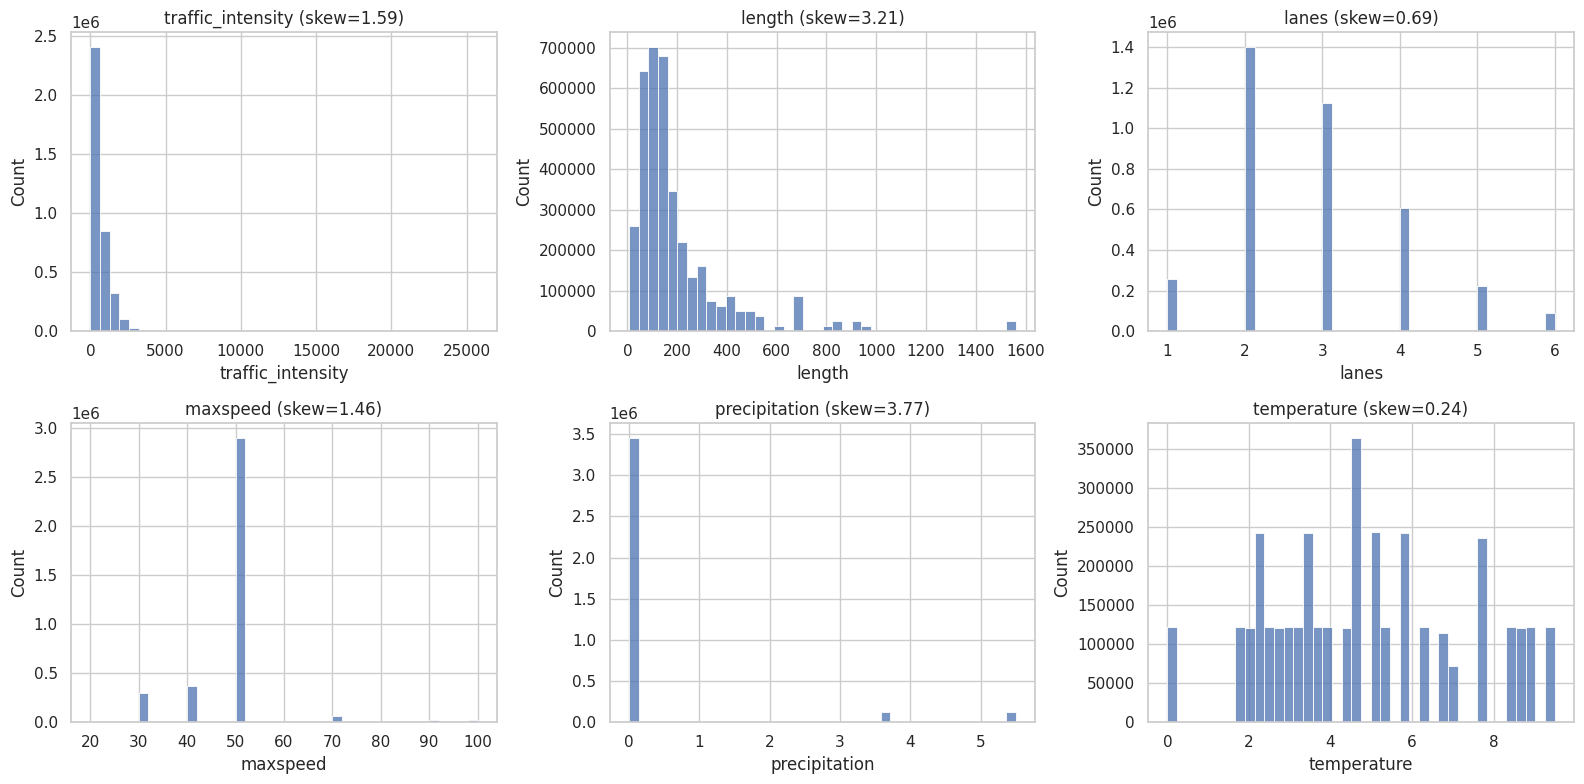

Proporsi traffic_intensity = 0 : 0.26 %
Proporsi precipitation = 0     : 93.4 %
Proporsi maxspeed = 50         : 78.4 %


In [8]:
cols = ['traffic_intensity','length','lanes','maxspeed','precipitation','temperature']
fig, ax = plt.subplots(2,3, figsize=(16,8))
for a,c in zip(ax.ravel(), cols):
    sns.histplot(df[c], kde=False, bins=40, ax=a); a.set_title(f'{c} (skew={df[c].skew():.2f})')
plt.tight_layout(); plt.savefig('figs/01_histogram.png', dpi=110); plt.show()
print('Proporsi traffic_intensity = 0 :', round((df['traffic_intensity']==0).mean()*100,2), '%')
print('Proporsi precipitation = 0     :', round((df['precipitation']==0).mean()*100,1), '%')
print('Proporsi maxspeed = 50         :', round((df['maxspeed']==50).mean()*100,1), '%')

### 5.2 Boxplot dan jumlah outlier

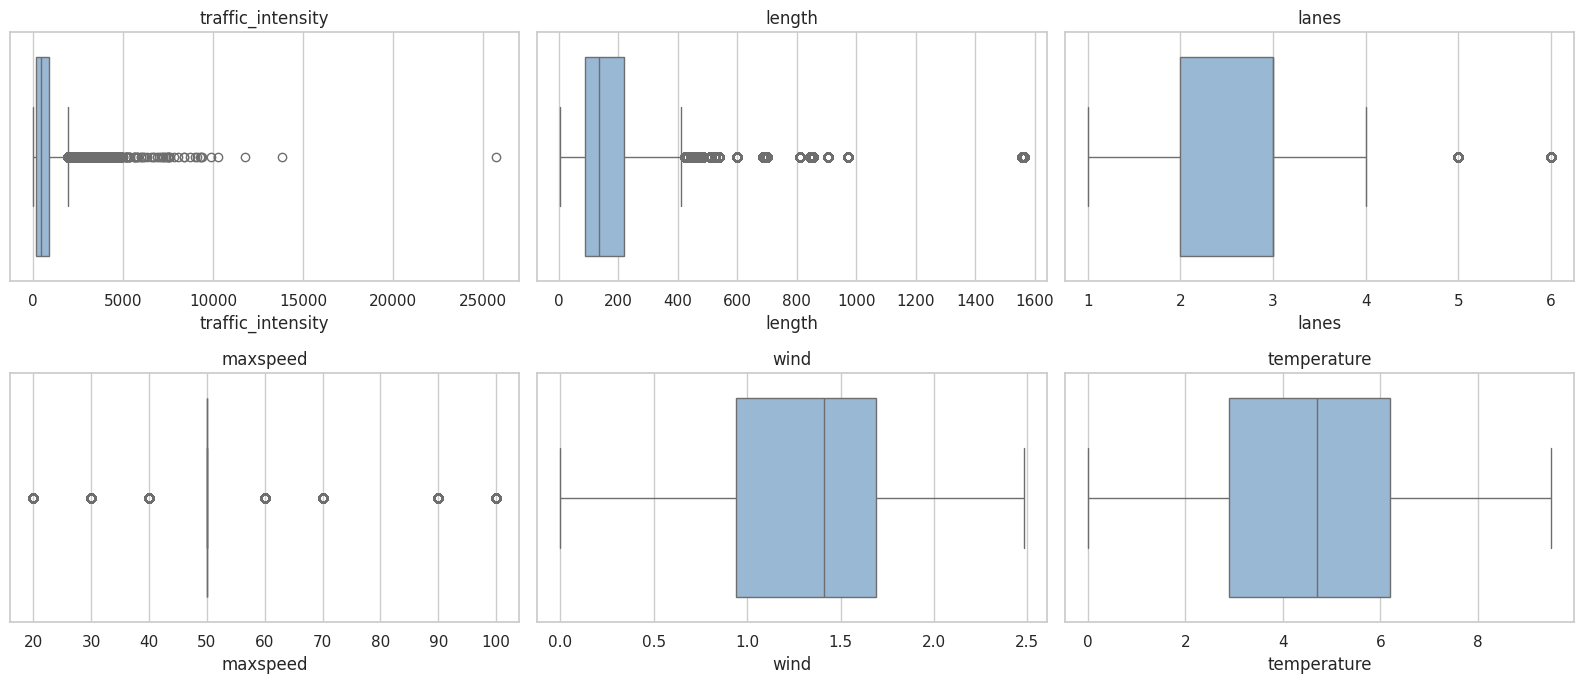

,jumlah outlier (aturan IQR)
longitude,61884
latitude,0
traffic_intensity,133755
wind,0
temperature,0
precipitation,242523
lanes,309731
maxspeed,798145
length,380990


In [9]:
fig, ax = plt.subplots(2,3, figsize=(16,7))
for a,c in zip(ax.ravel(), ['traffic_intensity','length','lanes','maxspeed','wind','temperature']):
    sns.boxplot(x=df[c], ax=a, color='#8fb8de'); a.set_title(c)
plt.tight_layout(); plt.savefig('figs/02_boxplot.png', dpi=110); plt.show()
out = {}
for c in num_cols:
    q1,q3 = df[c].quantile([.25,.75]); i=q3-q1
    out[c] = int(((df[c]<q1-1.5*i)|(df[c]>q3+1.5*i)).sum())
pd.Series(out, name='jumlah outlier (aturan IQR)').to_frame()

### 5.3 Pola waktu dan hubungan dengan lajur dan panjang ruas

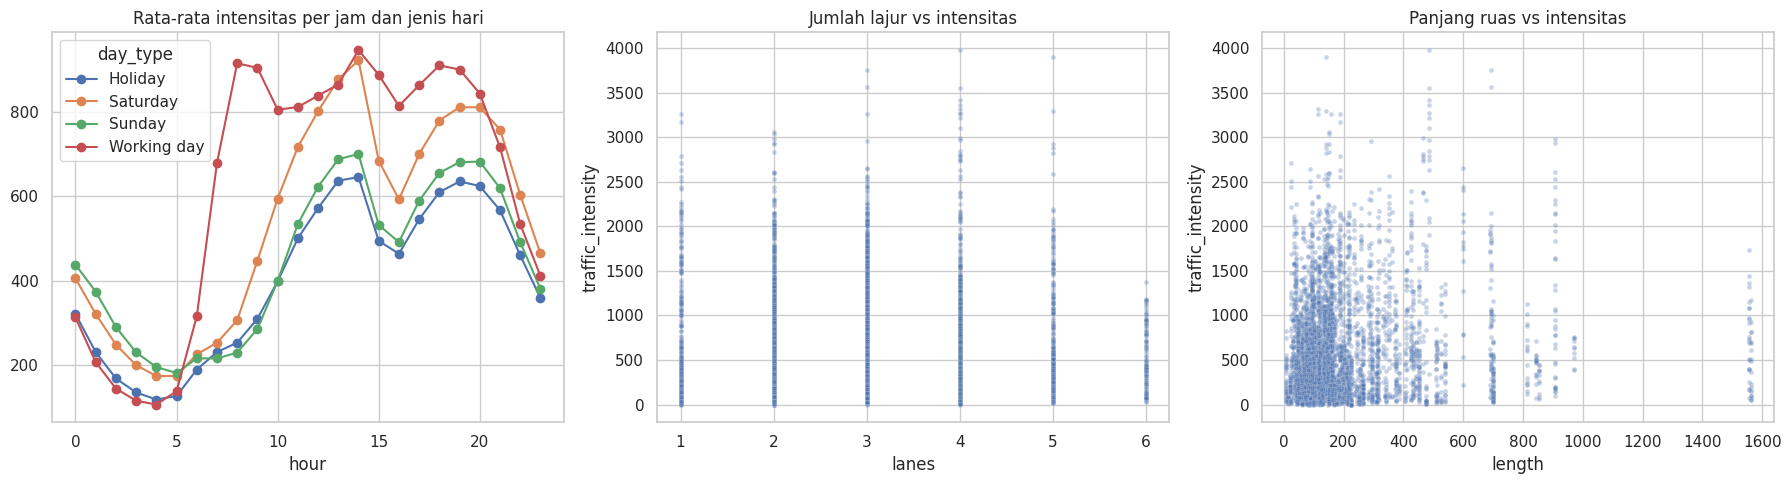

hour
0     331.7
1     232.5
2     167.0
3     133.4
4     120.3
5     144.1
6     296.3
7     594.7
8     791.1
9     793.1
10    732.0
11    760.4
12    797.9
13    831.5
14    900.5
15    821.9
16    754.1
17    811.6
18    862.1
19    858.8
20    812.2
21    696.9
22    525.4
23    405.1
Name: traffic_intensity, dtype: float64
corr intensitas-lanes : 0.14
corr intensitas-length: 0.12


In [10]:
df['hour'] = df['date'].dt.hour
fig, ax = plt.subplots(1,3, figsize=(18,5))
df.groupby(['hour','day_type'])['traffic_intensity'].mean().unstack().plot(ax=ax[0], marker='o'); ax[0].set_title('Rata-rata intensitas per jam dan jenis hari')
s = df.sample(min(5000,len(df)), random_state=42)
sns.scatterplot(data=s, x='lanes', y='traffic_intensity', alpha=.3, s=12, ax=ax[1]); ax[1].set_title('Jumlah lajur vs intensitas')
sns.scatterplot(data=s, x='length', y='traffic_intensity', alpha=.3, s=12, ax=ax[2]); ax[2].set_title('Panjang ruas vs intensitas')
plt.tight_layout(); plt.savefig('figs/03_pola_waktu_scatter.png', dpi=110); plt.show()
print(df.groupby('hour')['traffic_intensity'].mean().round(1))
print('corr intensitas-lanes :', round(df['traffic_intensity'].corr(df['lanes']),2))
print('corr intensitas-length:', round(df['traffic_intensity'].corr(df['length']),2))

### 5.4 Correlation heatmap

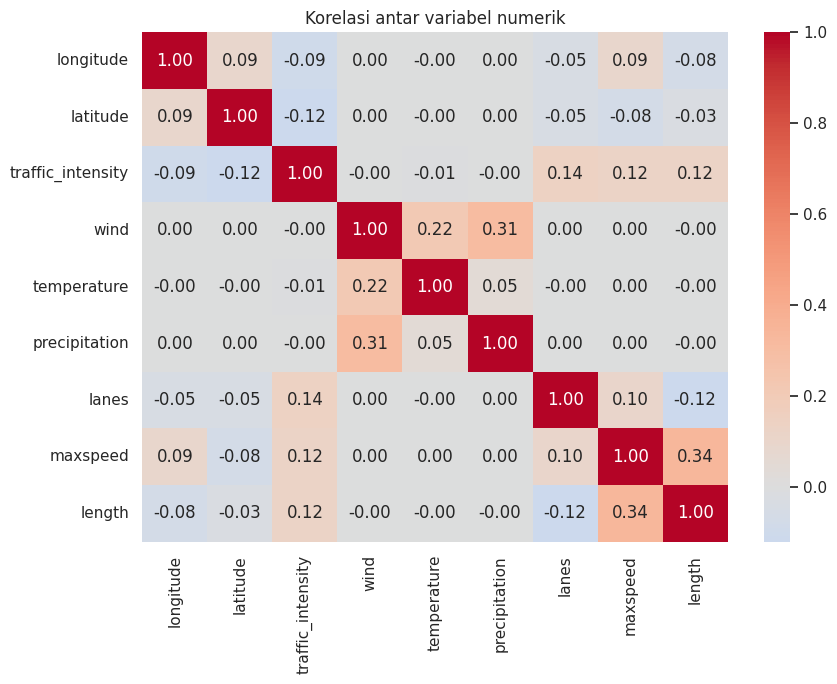

In [11]:
plt.figure(figsize=(9,7))
sns.heatmap(df[num_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Korelasi antar variabel numerik'); plt.tight_layout(); plt.savefig('figs/04_heatmap.png', dpi=110); plt.show()

### 5.5 Variabel kategorikal

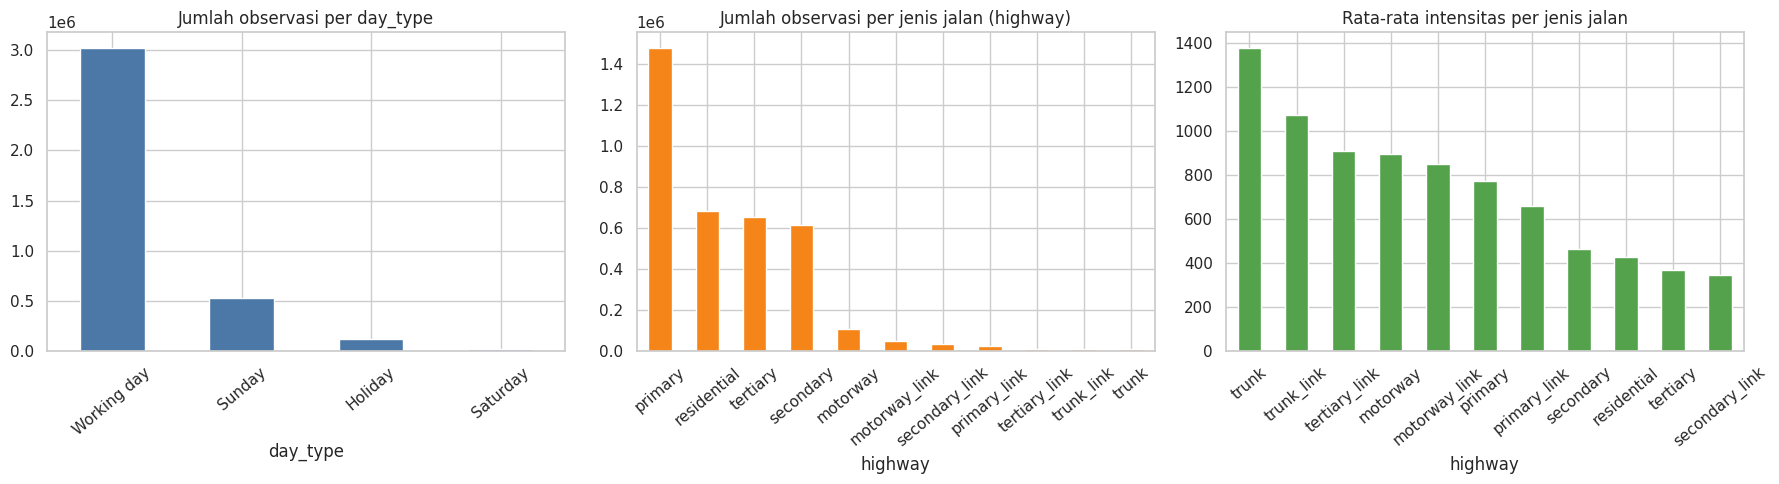

day_type  Holiday  Saturday  Sunday  Working day
date                                            
0           42955         0       0       485426
1           28298         0       0       499946
2           14319         0       0       513793
3           21391         0       0       507570
4           13996         0       0       515314
5               0     28593       0       499809
6               0         0  527898            0


In [12]:
fig, ax = plt.subplots(1,3, figsize=(18,5))
df['day_type'].value_counts().plot(kind='bar', ax=ax[0], color='#4c78a8', title='Jumlah observasi per day_type')
df['highway'].value_counts().plot(kind='bar', ax=ax[1], color='#f58518', title='Jumlah observasi per jenis jalan (highway)')
df.groupby('highway')['traffic_intensity'].mean().sort_values(ascending=False).plot(kind='bar', ax=ax[2], color='#54a24b', title='Rata-rata intensitas per jenis jalan')
for a in ax: a.tick_params(axis='x', rotation=40)
plt.tight_layout(); plt.savefig('figs/05_kategorikal.png', dpi=110); plt.show()
print(pd.crosstab(df['date'].dt.dayofweek, df['day_type']))

## 6. Data Quality Findings

In [13]:
q1,q3 = df['traffic_intensity'].quantile([.25,.75]); fence = q3+1.5*(q3-q1)
n_out = int((df['traffic_intensity']>fence).sum())
dow_sat = (df['date'].dt.dayofweek==5)
sat_labeled_working = float((df.loc[dow_sat,'day_type']=='Working day').mean()*100) if dow_sat.any() else float('nan')
rare = df['highway'].value_counts(normalize=True)
rows = [
 (1,'Distribusi traffic_intensity miring kanan dan banyak nilai ekstrem','mean=%.1f vs median=%.1f; max=%d; batas outlier IQR=%.0f; outlier=%d baris (%.1f%%)' % (df['traffic_intensity'].mean(), df['traffic_intensity'].median(), df['traffic_intensity'].max(), fence, n_out, n_out/len(df)*100),'Ekstrem mendominasi jarak Euclidean; gunakan log1p dan StandardScaler; outlier dipertahankan'),
 (2,'Label day_type tidak seimbang dan Sabtu mencurigakan','Saturday=%.1f%% baris; %.1f%% baris hari Sabtu berlabel Working day' % ((df['day_type']=='Saturday').mean()*100, sat_labeled_working),'Turunkan hari dalam minggu dari date; jangan pakai day_type mentah untuk Sabtu'),
 (3,'Jenis jalan (highway) tidak seimbang','primary=%.1f%%; paling jarang=%s (%.2f%%)' % (rare.iloc[0]*100, rare.index[-1], rare.iloc[-1]*100),'Gabungkan kategori langka/link ke kelompok induk (5 kelompok)'),
 (4,'Perbedaan skala antar variabel','traffic_intensity max=%d; wind max=%.2f; precipitation max=%.1f' % (df['traffic_intensity'].max(), df['wind'].max(), df['precipitation'].max()),'Wajib StandardScaler agar intensitas tidak mendominasi'),
 (5,'Kolom cuaca tampak sudah diskalakan/tidak dalam satuan asli; precipitation hampir selalu 0','temperature %.1f s.d. %.1f; precipitation=0 pada %.1f%% baris' % (df['temperature'].min(), df['temperature'].max(), (df['precipitation']==0).mean()*100),'Satuan tidak dilaporkan sebagai Celsius; precipitation dijadikan flag hujan; cuaca diuji dengan/tanpa'),
 (6,'Intensitas bernilai 0','Jumlah baris intensitas=0: %d (%.2f%%)' % ((df['traffic_intensity']==0).sum(), (df['traffic_intensity']==0).mean()*100),'Periksa apakah malam hari wajar atau sensor mati; dipertahankan (log1p aman untuk 0)'),
 (7,'Kolom redundan / bukan fitur numerik','original_point & closest_point (WKT) memuat info koordinat yang sama dengan longitude/latitude; id bertipe angka tetapi kode sensor','Buang kolom WKT dari fitur; id dipakai sebagai metadata, bukan fitur numerik'),
 (8,'Missing value dan duplikat','Missing=%d; duplikat=%d' % (df.isna().sum().sum(), df.duplicated().sum()),'Data bersih dari sisi ini (hasil pembersihan penulis); imputer tetap dipasang sebagai pengaman'),
]
dq = pd.DataFrame(rows, columns=['No','Temuan','Bukti','Implikasi'])
dq.style.set_properties(**{'text-align':'left','white-space':'pre-wrap'})

,No,Temuan,Bukti,Implikasi
0,1,Distribusi traffic_intensity miring kanan dan banyak nilai ekstrem,mean=591.4 vs median=412.8; max=25734; batas outlier IQR=1918; outlier=133755 baris (3.6%),Ekstrem mendominasi jarak Euclidean; gunakan log1p dan StandardScaler; outlier dipertahankan
1,2,Label day_type tidak seimbang dan Sabtu mencurigakan,Saturday=0.8% baris; 94.6% baris hari Sabtu berlabel Working day,Turunkan hari dalam minggu dari date; jangan pakai day_type mentah untuk Sabtu
2,3,Jenis jalan (highway) tidak seimbang,primary=40.1%; paling jarang=trunk (0.32%),Gabungkan kategori langka/link ke kelompok induk (5 kelompok)
3,4,Perbedaan skala antar variabel,traffic_intensity max=25734; wind max=2.48; precipitation max=5.5,Wajib StandardScaler agar intensitas tidak mendominasi
4,5,Kolom cuaca tampak sudah diskalakan/tidak dalam satuan asli; precipitation hampir selalu 0,temperature 0.0 s.d. 9.5; precipitation=0 pada 93.4% baris,Satuan tidak dilaporkan sebagai Celsius; precipitation dijadikan flag hujan; cuaca diuji dengan/tanpa
5,6,Intensitas bernilai 0,Jumlah baris intensitas=0: 9471 (0.26%),Periksa apakah malam hari wajar atau sensor mati; dipertahankan (log1p aman untuk 0)
6,7,Kolom redundan / bukan fitur numerik,original_point & closest_point (WKT) memuat info koordinat yang sama dengan longitude/latitude; id bertipe angka tetapi kode sensor,"Buang kolom WKT dari fitur; id dipakai sebagai metadata, bukan fitur numerik"
7,8,Missing value dan duplikat,Missing=0; duplikat=0,Data bersih dari sisi ini (hasil pembersihan penulis); imputer tetap dipasang sebagai pengaman


## 7. Preprocessing Plan
| Masalah | Variabel | Rencana Penanganan | Alasan |
|---|---|---|---|
| Missing value | Seluruh kolom (0 pada seluruh data) | Tidak ada imputasi; `SimpleImputer` dipasang di pipeline sebagai pengaman | Pipeline tetap berjalan bila data baru memiliki nilai kosong |
| Duplikat | Seluruh baris | Cek `duplicated()` dan hapus bila ada | Mencegah bobot ganda |
| Outlier dan distribusi miring | `traffic_intensity`, `length` | Outlier dipertahankan; transformasi `log1p` pada intensitas | Ekstrem adalah kondisi padat yang ingin dikelompokkan; log1p meredam dominasinya |
| Kategori tidak seimbang | `highway` (11 kategori) | Digabung menjadi 5 kelompok (motorway/trunk, primary, secondary, tertiary, residential) lalu one-hot | Kategori langka (sekitar 0,3%) terlalu sedikit untuk membentuk pola sendiri |
| Label hari tidak konsisten | `day_type` | Turunkan `is_non_working` dan hari dalam minggu dari `date`; `day_type` mentah tidak dipakai langsung | Hanya 5,4% hari Sabtu berlabel Saturday; 94,6% berlabel Working day |
| Perbedaan skala | Seluruh numerik | `StandardScaler` | Clustering berbasis jarak sensitif skala |
| Variabel waktu siklik | `date` (jam) | Encoding sin/cos jam, dan kelompok periode (dini hari, pagi, siang, sore, malam) | Jam 23 dan jam 0 sebenarnya berdekatan |
| Cuaca | `wind`, `temperature`, `precipitation` | Tidak dimasukkan di model awal; diuji dengan/tanpa (precipitation menjadi flag hujan) | Satuan tidak jelas dan kontribusinya belum terbukti |
| Kolom redundan | `original_point`, `closest_point`, `id`, `name` | Dikeluarkan dari fitur; `id`, `name`, koordinat disimpan sebagai metadata profiling | Duplikat dari koordinat; id adalah kode, bukan ukuran |

## 8. Initial Feature Engineering

In [14]:
fe = df.copy()
fe['hour']  = fe['date'].dt.hour
fe['dow']   = fe['date'].dt.dayofweek
fe['is_non_working'] = ((fe['dow']>=5) | (fe['day_type']!='Working day')).astype(int)
fe['hour_sin'] = np.sin(2*np.pi*fe['hour']/24); fe['hour_cos'] = np.cos(2*np.pi*fe['hour']/24)
fe['time_period'] = pd.cut(fe['hour'], bins=[-1,5,9,15,19,23], labels=['Dini hari','Pagi','Siang','Sore','Malam'])
fe['log_intensity'] = np.log1p(fe['traffic_intensity'])
fe['intensity_per_lane'] = fe['traffic_intensity'] / fe['lanes']
# rel_intensity memakai rata-rata sensor dari DATA LATIH saja (date < CUTOFF) agar tidak bocor dari periode uji
sensor_mean_train = fe.loc[fe['date'] < CUTOFF].groupby('id')['traffic_intensity'].mean().replace(0, np.nan)
fe['rel_intensity'] = fe['traffic_intensity'] / fe['id'].map(sensor_mean_train)   # NaN bila sensor tidak ada di data latih (diisi imputer)
fe['is_rain'] = (fe['precipitation']>0).astype(int)
hw = {'motorway':'motorway_trunk','motorway_link':'motorway_trunk','trunk':'motorway_trunk','trunk_link':'motorway_trunk',
      'primary':'primary','primary_link':'primary','secondary':'secondary','secondary_link':'secondary',
      'tertiary':'tertiary','tertiary_link':'tertiary','residential':'residential'}
fe['highway_group'] = fe['highway'].map(hw).fillna('residential')
new = ['hour_sin','hour_cos','is_non_working','log_intensity','intensity_per_lane','rel_intensity','is_rain']
print(fe[new].describe().T.round(3))
print(fe['time_period'].value_counts()); print(fe['highway_group'].value_counts())

                        count     mean      std  min     25%      50%      75%       max
hour_sin            3699308.0   -0.002    0.707 -1.0  -0.707    0.000    0.707     1.000
hour_cos            3699308.0   -0.001    0.707 -1.0  -0.707   -0.000    0.707     1.000
is_non_working      3699308.0    0.318    0.466  0.0   0.000    0.000    1.000     1.000
log_intensity       3699308.0    5.786    1.303  0.0   5.037    6.025    6.757    10.156
intensity_per_lane  3699308.0  235.178  285.102  0.0  58.750  148.625  313.750  9336.500
rel_intensity       3699308.0    0.986    0.623  0.0   0.433    0.998    1.442    34.671
is_rain             3699308.0    0.066    0.248  0.0   0.000    0.000    0.000     1.000
time_period
Siang        926092
Dini hari    920434
Sore         618275
Malam        617491
Pagi         617016
Name: count, dtype: int64
highway_group
primary           1507490
residential        684103
tertiary           666638
secondary          656274
motorway_trunk     184803
Name: 

| Kandidat Fitur | Dibentuk dari | Alasan |
|---|---|---|
| `intensity_per_lane` (rasio) | `traffic_intensity` / `lanes` | Beban per lajur: jalan 3 lajur dengan 600 kendaraan berbeda tingkat kepadatannya dengan jalan 1 lajur |
| `rel_intensity` (interaksi/normalisasi) | `traffic_intensity` / rata-rata intensitas sensor yang sama (dihitung dari data latih saja) | Mengukur seberapa padat sebuah jam dibanding kebiasaan sensor itu, sehingga lokasi dan waktu terhubung |
| `hour_sin`, `hour_cos` (transformasi) | Jam dari `date` | Jam bersifat siklik (23 dan 0 berdekatan) |
| `time_period` (pengelompokan nilai) | Jam dari `date` | Dini hari, pagi, siang, sore, malam; untuk profiling klaster |
| `log_intensity` (transformasi) | `log1p(traffic_intensity)` | Meredam kemiringan kanan |
| `is_non_working` | `date` dan `day_type` | Memisahkan hari kerja dari akhir pekan/libur dengan Sabtu yang benar |
| `highway_group` (pengelompokan) | `highway` (11 menjadi 5 kelompok) | Mengatasi kategori langka |
| `is_rain` | `precipitation` > 0 | Precipitation hampir selalu 0, flag lebih bermakna |

## 9. Initial Data Pipeline

In [15]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

fe['oneway_flag'] = fe['oneway'].astype(int)
num_features = ['log_intensity','intensity_per_lane','rel_intensity','hour_sin','hour_cos','lanes','maxspeed','length']
bin_features = ['is_non_working','oneway_flag']
cat_features = ['highway_group']
# Diuji pada tahap modeling: wind, temperature, is_rain
meta = fe[['id','name','date','latitude','longitude','highway','highway_group','day_type','time_period','traffic_intensity']].copy()

pre = ColumnTransformer([
    ('num', Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler())]), num_features),
    ('bin', SimpleImputer(strategy='most_frequent'), bin_features),
    ('cat', Pipeline([('imp', SimpleImputer(strategy='most_frequent')), ('oh', OneHotEncoder(handle_unknown='ignore'))]), cat_features),
])
is_tr = (fe['date'] < CUTOFF).values
pre.fit(fe.loc[is_tr])          # fit HANYA pada data latih (mencegah kebocoran dari periode uji)
X = pre.transform(fe)
X_df = pd.DataFrame(X.toarray() if hasattr(X,'toarray') else X, columns=pre.get_feature_names_out())
print('Shape X:', X_df.shape, '| NaN:', int(X_df.isna().sum().sum()))
print('Rata-rata/std kolom numerik (sekitar 0 dan 1 pada data latih; sedikit berbeda pada seluruh data):')
print(X_df[[c for c in X_df.columns if c.startswith('num__')]].agg(['mean','std']).round(2))
X_df.head()

Shape X: (3699308, 15) | NaN: 0
Rata-rata/std kolom numerik (sekitar 0 dan 1 pada data latih; sedikit berbeda pada seluruh data):
      num__log_intensity  num__intensity_per_lane  num__rel_intensity  num__hour_sin  num__hour_cos  num__lanes  num__maxspeed  num__length
mean               -0.01                    -0.01               -0.02           -0.0           -0.0         0.0            0.0         -0.0
std                 1.00                     0.98                0.99            1.0            1.0         1.0            1.0          1.0


,num__log_intensity,num__intensity_per_lane,num__rel_intensity,num__hour_sin,num__hour_cos,num__lanes,num__maxspeed,num__length,bin__is_non_working,bin__oneway_flag,cat__highway_group_motorway_trunk,cat__highway_group_primary,cat__highway_group_residential,cat__highway_group_secondary,cat__highway_group_tertiary
0,-0.407083,-0.491675,-0.715667,0.001966,1.415832,-0.74828,0.198076,-0.458301,0.0,1.0,0.0,0.0,0.0,0.0,1.0
1,-0.814932,-0.629850,-1.077681,0.367933,1.367636,-0.74828,0.198076,-0.458301,0.0,1.0,0.0,0.0,0.0,0.0,1.0
2,-1.126602,-0.695483,-1.249638,0.708959,1.226332,-0.74828,0.198076,-0.458301,0.0,1.0,0.0,0.0,0.0,0.0,1.0
3,-1.260943,-0.716497,-1.304694,1.001804,1.001550,-0.74828,0.198076,-0.458301,0.0,1.0,0.0,0.0,0.0,0.0,1.0
4,-1.065797,-0.684688,-1.221356,1.226513,0.708608,-0.74828,0.198076,-0.458301,0.0,1.0,0.0,0.0,0.0,0.0,1.0


In [16]:
os.makedirs('data', exist_ok=True)
X_df.to_csv('data/processed_features_B03.csv', index=False)
meta.to_csv('data/metadata_B03.csv', index=False)
print('Tersimpan: data/processed_features_B03.csv dan data/metadata_B03.csv')

Tersimpan: data/processed_features_B03.csv dan data/metadata_B03.csv


## 10. Ringkasan Data

In [17]:
print('Observasi:', len(fe), '| sensor:', fe['id'].nunique(), '| periode:', fe['date'].min(), 's.d.', fe['date'].max())
print('Missing value pada kolom asli:', int(df.isna().sum().sum()))
print('Matriks fitur awal (bagian 9):', X_df.shape)

Observasi: 3699308 | sensor: 300 | periode: 2022-06-01 00:00:00 s.d. 2023-10-31 23:00:00
Missing value pada kolom asli: 0
Matriks fitur awal (bagian 9): (3699308, 15)


---
# BAGIAN II. Modeling Clustering

In [18]:
# Hemat memori sebelum modeling: buang kolom WKT dan variabel Bagian I yang tidak dipakai lagi
import gc
fe = fe.drop(columns=[c for c in ['original_point','closest_point'] if c in fe.columns])
for v in ['df','X','X_df','meta']:
    globals().pop(v, None)
gc.collect()
print('fe:', fe.shape)

fe: (3699308, 27)


## Konfigurasi Modeling

In [19]:
import os, time, warnings, sys
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import sklearn
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score, adjusted_rand_score
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid'); os.makedirs('figs', exist_ok=True)

# ---------- KONFIGURASI ----------
SEED     = 42          # random seed untuk semua eksperimen
N_MODEL  = 100_000     # ukuran sampel kerja (data latih)
N_TEST   = 100_000     # ukuran sampel data uji (evaluasi hold-out, Bagian III)
SILH_N   = 20_000      # ukuran sub-sampel untuk Silhouette
HIER_N   = 8_000       # sampel untuk Hierarchical (mahal secara memori)
DBSCAN_N = 30_000      # sampel untuk DBSCAN
K_RANGE  = range(2, 11)

# Data sudah dimuat pada Bagian I (variabel fe), tidak dimuat ulang di sini.

LOG = []   # catatan eksperimen (parameter, seed, metrik)
def log(exp, algo, params, metrics, note=''):
    LOG.append({'eksperimen':exp,'algoritma':algo,'parameter':params,'seed':SEED, **metrics, 'catatan':note})

print('scikit-learn', sklearn.__version__, '| pandas', pd.__version__, '| python', sys.version.split()[0])

scikit-learn 1.6.1 | pandas 2.2.3 | python 3.13.18


## 11. Desain Evaluasi dan Pembagian Data
| Komponen | Rancangan |
|---|---|
| Pembagian data | Hold-out temporal: latih 1 Juni 2022 - 30 Juni 2023; uji 1 Juli - 31 Oktober 2023 |
| Alasan | Jam bersebelahan pada sensor yang sama sangat mirip; pembagian acak membocorkan informasi ke data uji |
| Seleksi model | Hanya data latih (K, fitur set, algoritma, PCA); data uji dipakai sekali pada bagian 21-22 |
| Metrik | Silhouette (sub-sampel 20.000), Davies-Bouldin, Calinski-Harabasz, ARI (kesamaan dua pengelompokan) |
| Validasi | Hold-out temporal; kestabilan antar-seed (bagian 18); antar-periode dan refit pada data uji (bagian 22) |
| Baseline | B0 label acak, B1 aturan periode waktu, B2 aturan kelas jalan, B3 aturan jam sepi x motorway/trunk; K-Means sebagai baseline algoritmik (bagian 14) |

| Risiko data leakage | Kontrol |
|---|---|
| Imputer, scaler, encoder dipelajari dari data uji | Pipeline di-fit pada sampel latih, data uji hanya di-transform (bagian 13, 21) |
| Statistik per sensor (`rel_intensity`) memakai seluruh periode | Rata-rata sensor dihitung dari data latih saja (bagian 8, 11) |
| PCA di-fit pada seluruh data | PCA berada di dalam Pipeline dan di-fit pada sampel latih (bagian 17) |
| Pemilihan model memakai data uji | Seleksi hanya dari data latih (bagian 14-19) |
| Pembagian acak pada deret waktu | Pembagian temporal (bagian 11) |
| Sensor yang hanya muncul di periode uji | Nilai kosong diisi median data latih oleh imputer |

In [20]:
# Pembagian data berdasarkan waktu (hold-out temporal)
is_train = (fe['date'] < CUTOFF).values
fe['split'] = np.where(is_train, 'latih', 'uji')

# rel_intensity: rata-rata sensor dihitung dari DATA LATIH saja (idempoten dengan Bagian I)
sm_tr = fe.loc[is_train].groupby('id')['traffic_intensity'].mean().replace(0, np.nan)
fe['rel_intensity'] = fe['traffic_intensity'] / fe['id'].map(sm_tr)

ring = fe.groupby('split')['date'].agg(['min','max','count'])
ring['persen'] = (ring['count']/len(fe)*100).round(1)
print(ring)
ids_tr, ids_te = set(fe.loc[is_train,'id'].unique()), set(fe.loc[~is_train,'id'].unique())
print('Sensor latih:', len(ids_tr), '| sensor uji:', len(ids_te), '| sensor uji yang tidak ada di data latih:', len(ids_te-ids_tr))
print('rel_intensity kosong (NaN):', int(fe['rel_intensity'].isna().sum()), '(akan diisi median latih oleh imputer)')

             min                 max    count  persen
split                                                
latih 2022-06-01 2023-06-30 23:00:00  2821386    76.3
uji   2023-07-01 2023-10-31 23:00:00   877922    23.7
Sensor latih: 300 | sensor uji: 300 | sensor uji yang tidak ada di data latih: 0
rel_intensity kosong (NaN): 0 (akan diisi median latih oleh imputer)


## 12. Fitur yang Digunakan
| Kelompok | Fitur Set A (baseline) | Perlakuan |
|---|---|---|
| Numerik | `log_intensity`, `intensity_per_lane`, `rel_intensity`, `hour_sin`, `hour_cos`, `lanes`, `maxspeed`, `length` | Imputasi median, StandardScaler |
| Biner | `is_non_working`, `oneway_flag` | Apa adanya |
| Kategorikal | `highway_group` (5 kelompok) | One-hot |

Fitur Set B = Set A + `wind`, `temperature`, `is_rain` (diuji pada bagian 15). Tidak dipakai sebagai fitur: `id`, koordinat, `original_point`, `closest_point`, `name` (hanya untuk profiling).

## 13. Preprocessing dan Scaling

In [21]:
num_A = ['log_intensity','intensity_per_lane','rel_intensity','hour_sin','hour_cos','lanes','maxspeed','length']
bin_A = ['is_non_working','oneway_flag']
cat_A = ['highway_group']
num_B = num_A + ['wind','temperature']
bin_B = bin_A + ['is_rain']

def make_pre(num, binf, cat):
    try:    oh = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
    except TypeError: oh = OneHotEncoder(handle_unknown='ignore', sparse=False)
    return ColumnTransformer([
        ('num', Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler())]), num),
        ('bin', SimpleImputer(strategy='most_frequent'), binf),
        ('cat', Pipeline([('imp', SimpleImputer(strategy='most_frequent')), ('oh', oh)]), cat)])

# sampel kerja acak dari DATA LATIH saja
work = fe[is_train].sample(n=min(N_MODEL, int(is_train.sum())), random_state=SEED).reset_index(drop=True)
pre_A = make_pre(num_A, bin_A, cat_A)
X = np.asarray(pre_A.fit_transform(work), dtype=float)
feature_names = pre_A.get_feature_names_out()
print('Sampel kerja:', work.shape, '| matriks fitur X:', X.shape, '| NaN:', int(np.isnan(X).sum()))
print('Rata-rata kolom numerik (harus sekitar 0):', X[:, :8].mean(axis=0).round(3))
print('Std kolom numerik (harus sekitar 1)      :', X[:, :8].std(axis=0).round(3))

Sampel kerja: (100000, 28) | matriks fitur X: (100000, 15) | NaN: 0
Rata-rata kolom numerik (harus sekitar 0): [ 0.  0.  0.  0.  0.  0. -0.  0.]
Std kolom numerik (harus sekitar 1)      : [1. 1. 1. 1. 1. 1. 1. 1.]


### Fungsi evaluasi

In [22]:
def evaluate(Xe, labels, n=SILH_N, seed=SEED):
    labels = np.asarray(labels); mask = labels != -1          # -1 = noise (DBSCAN)
    Xm, lm = Xe[mask], labels[mask]
    out = {'silhouette': np.nan, 'davies_bouldin': np.nan, 'calinski_harabasz': np.nan}
    if len(np.unique(lm)) < 2: return out
    try:
        out['silhouette'] = silhouette_score(Xm, lm, sample_size=min(n, len(Xm)), random_state=seed)
        out['davies_bouldin'] = davies_bouldin_score(Xm, lm)
        out['calinski_harabasz'] = calinski_harabasz_score(Xm, lm)
    except Exception as e:
        print('evaluate gagal:', e)
    return out

## 14. K-Means: Baseline Algoritmik dan Pengujian Beberapa Nilai K

In [23]:
rows = []
for k in K_RANGE:
    t0 = time.time()
    km = KMeans(n_clusters=k, n_init=5, random_state=SEED).fit(X)
    m = evaluate(X, km.labels_)
    rows.append({'k':k, 'inertia':km.inertia_, **m, 'detik': round(time.time()-t0,1)})
    log('Sweep K (Fitur Set A)', 'KMeans', f'k={k}, n_init=5', m)
kres = pd.DataFrame(rows).round(4); kres

,k,inertia,silhouette,davies_bouldin,calinski_harabasz,detik
0,2,720365.9362,0.2097,1.7627,26887.2648,6.1
1,3,645102.5158,0.2175,1.6023,20845.2000,8.1
2,4,588734.8659,0.1759,1.8380,18418.5756,6.2
3,5,540933.3957,0.1782,1.6864,17243.5655,8.5
4,6,507134.1625,0.1735,1.6238,16046.9748,6.5
5,7,480191.2884,0.1478,1.7377,15057.7291,7.6
6,8,457630.4491,0.1455,1.6906,14247.0095,7.7
7,9,438473.7426,0.1406,1.6239,13556.6916,7.9
8,10,422283.9042,0.1462,1.5898,12938.2238,7.6


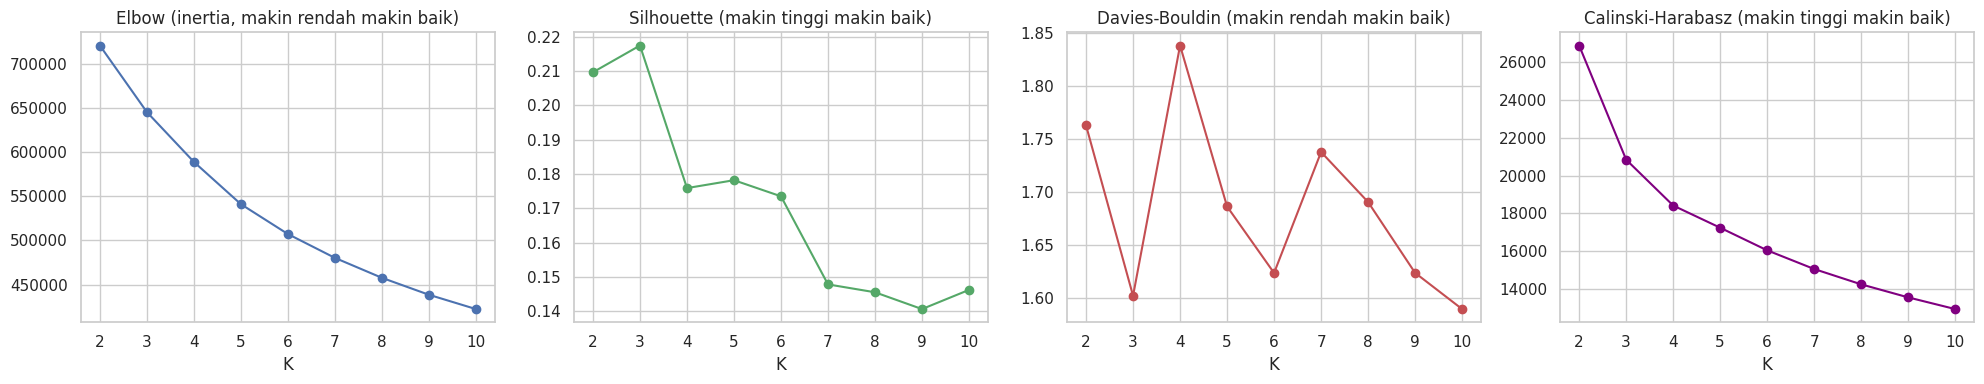

In [24]:
fig, ax = plt.subplots(1,4, figsize=(20,4))
ax[0].plot(kres.k, kres.inertia, marker='o'); ax[0].set_title('Elbow (inertia, makin rendah makin baik)')
ax[1].plot(kres.k, kres.silhouette, marker='o', color='g'); ax[1].set_title('Silhouette (makin tinggi makin baik)')
ax[2].plot(kres.k, kres.davies_bouldin, marker='o', color='r'); ax[2].set_title('Davies-Bouldin (makin rendah makin baik)')
ax[3].plot(kres.k, kres.calinski_harabasz, marker='o', color='purple'); ax[3].set_title('Calinski-Harabasz (makin tinggi makin baik)')
for a in ax: a.set_xlabel('K')
plt.tight_layout(); plt.savefig('figs/10_sweep_k.png', dpi=110); plt.show()

In [25]:
# K akhir: default = K dengan Silhouette tertinggi. Setelah melihat grafik, GANTI manual bila perlu, mis. K_FINAL = 4
K_FINAL = int(kres.loc[kres['silhouette'].idxmax(), 'k'])
print('K_FINAL =', K_FINAL)

K_FINAL = 3


## 15. Perbandingan Fitur Set A vs B (dengan Cuaca)

In [26]:
pre_B = make_pre(num_B, bin_B, cat_A)
XB = np.asarray(pre_B.fit_transform(work), dtype=float)
kmA = KMeans(K_FINAL, n_init=5, random_state=SEED).fit(X)
kmB = KMeans(K_FINAL, n_init=5, random_state=SEED).fit(XB)
res = pd.DataFrame([
  {'set':'A (tanpa cuaca) di ruang A', **evaluate(X, kmA.labels_)},
  {'set':'B (+cuaca) di ruang B',      **evaluate(XB, kmB.labels_)},
  {'set':'B (+cuaca) dinilai di ruang A', **evaluate(X, kmB.labels_)}]).round(4)
ari_AB = adjusted_rand_score(kmA.labels_, kmB.labels_)
for r in res.to_dict('records'):
    log('Fitur Set A vs B', 'KMeans', f"K={K_FINAL}; {r['set']}", {k:r[k] for k in ['silhouette','davies_bouldin','calinski_harabasz']}, f'ARI(A,B)={ari_AB:.3f}')
print('ARI antara label Set A dan Set B:', round(ari_AB,3)); res

ARI antara label Set A dan Set B: 0.859


,set,silhouette,davies_bouldin,calinski_harabasz
0,A (tanpa cuaca) di ruang A,0.2175,1.6023,20845.2000
1,B (+cuaca) di ruang B,0.1637,2.0998,15316.0709
2,B (+cuaca) dinilai di ruang A,0.2061,1.8527,20163.1143


## 16. Algoritma Alternatif: Hierarchical dan DBSCAN

In [27]:
rs = np.random.RandomState(SEED)
# --- Hierarchical (Ward) ---
idx_h = rs.choice(len(X), min(HIER_N, len(X)), replace=False); Xh = X[idx_h]
t0=time.time(); ag = AgglomerativeClustering(n_clusters=K_FINAL, linkage='ward').fit(Xh); t_ag=time.time()-t0
km_h = KMeans(K_FINAL, n_init=5, random_state=SEED).fit(Xh)
m_ag, m_kmh = evaluate(Xh, ag.labels_), evaluate(Xh, km_h.labels_)
ari_h = adjusted_rand_score(ag.labels_, km_h.labels_)
log('Alternatif', 'Agglomerative (Ward)', f'K={K_FINAL}, n={len(Xh)}', m_ag, f'ARI vs KMeans={ari_h:.3f}')
log('Alternatif', 'KMeans (sub-sampel sama)', f'K={K_FINAL}, n={len(Xh)}', m_kmh)
pd.DataFrame([{'algoritma':'KMeans', **m_kmh}, {'algoritma':'Agglomerative (Ward)', **m_ag}]).round(4).assign(ARI_vs_KMeans=[1.0, round(ari_h,3)])

,algoritma,silhouette,davies_bouldin,calinski_harabasz,ARI_vs_KMeans
0,KMeans,0.1893,1.9679,1613.3455,1.000
1,Agglomerative (Ward),0.1718,1.8259,1268.7374,0.397


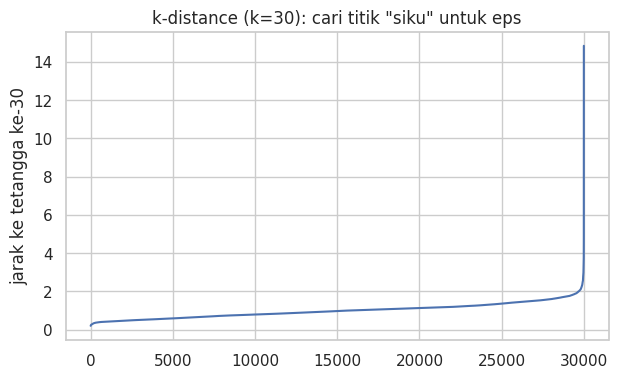

Persentil jarak (50/90/95/99): [0.969 1.502 1.662 2.007]


In [28]:
# --- DBSCAN: pilih eps lewat grafik k-distance ---
idx_d = rs.choice(len(X), min(DBSCAN_N, len(X)), replace=False); Xd = X[idx_d]
MIN_SAMPLES = 30
nn = NearestNeighbors(n_neighbors=MIN_SAMPLES).fit(Xd)
kd = np.sort(nn.kneighbors(Xd)[0][:, -1])
plt.figure(figsize=(7,4)); plt.plot(kd); plt.title(f'k-distance (k={MIN_SAMPLES}): cari titik "siku" untuk eps')
plt.ylabel('jarak ke tetangga ke-30'); plt.savefig('figs/11_kdistance.png', dpi=110); plt.show()
print('Persentil jarak (50/90/95/99):', np.percentile(kd,[50,90,95,99]).round(3))

In [29]:
rows = []; dbscan_sizes = {}
for eps in [0.5, 0.8, 1.0, 1.5, 2.0]:
    lab = DBSCAN(eps=eps, min_samples=MIN_SAMPLES).fit_predict(Xd)
    ncl = len(set(lab)) - (1 if -1 in lab else 0); noise = (lab==-1).mean()*100
    m = evaluate(Xd, lab)
    dbscan_sizes[eps] = pd.Series(lab).value_counts().head(8)
    del lab
    rows.append({'eps':eps, 'jumlah_cluster':ncl, 'noise_%':round(noise,1), **m})
    log('Alternatif', 'DBSCAN', f'eps={eps}, min_samples={MIN_SAMPLES}, n={len(Xd)}', m, f'cluster={ncl}, noise={noise:.1f}%')
gc.collect()
for e in (1.5, 2.0):
    print(f'eps = {e}: ukuran cluster terbesar (-1 = noise)'); print(dbscan_sizes[e].to_string()); print()
pd.DataFrame(rows).round(4)

eps = 1.5: ukuran cluster terbesar (-1 = noise)
 0    27874
-1      640
 1      472
 2      331
 5      155
 4       99
 3       71
 7       62

eps = 2.0: ukuran cluster terbesar (-1 = noise)
 0    28881
 2      484
 3      410
 1      182
-1       43



,eps,jumlah_cluster,noise_%,silhouette,davies_bouldin,calinski_harabasz
0,0.5,21,81.7,-0.1006,1.2603,232.6683
1,0.8,54,49.4,-0.1219,1.7717,261.2608
2,1.0,39,31.4,-0.1457,1.8860,284.2885
3,1.5,15,2.1,-0.0553,1.2678,390.1785
4,2.0,4,0.1,0.2735,1.2498,1274.7628


## 17. PCA

Fitur awal: 15 | komponen untuk 90% varians: 8 | untuk 95%: 10


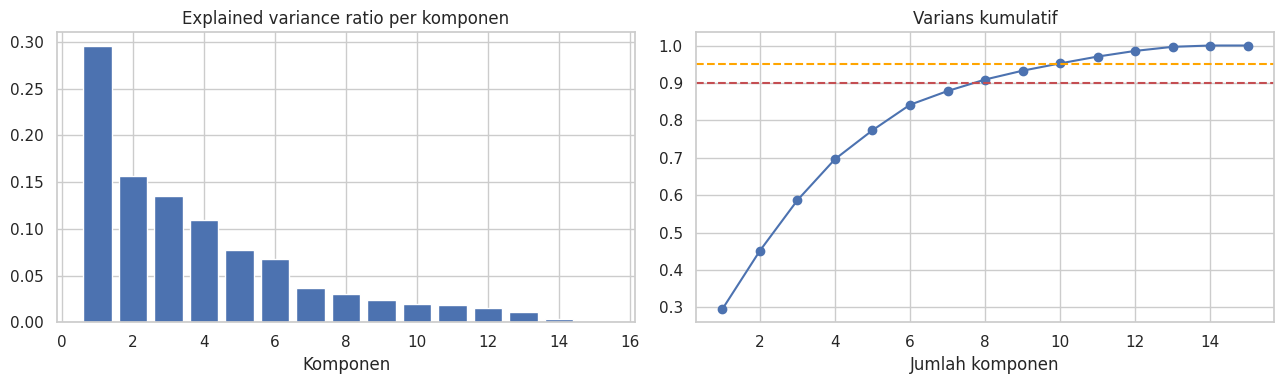

,komponen,explained_variance_ratio,kumulatif
0,1,0.2955,0.2955
1,2,0.1560,0.4515
2,3,0.1350,0.5866
3,4,0.1096,0.6962
4,5,0.0773,0.7735
5,6,0.0682,0.8416
6,7,0.0367,0.8783
7,8,0.0308,0.9091
8,9,0.0236,0.9327
9,10,0.0195,0.9522


In [30]:
pca_full = PCA(random_state=SEED).fit(X)
evr = pca_full.explained_variance_ratio_; cum = np.cumsum(evr)
n90 = int(np.searchsorted(cum, 0.90) + 1); n95 = int(np.searchsorted(cum, 0.95) + 1)
print(f'Fitur awal: {X.shape[1]} | komponen untuk 90% varians: {n90} | untuk 95%: {n95}')
fig, ax = plt.subplots(1,2, figsize=(13,4))
ax[0].bar(range(1,len(evr)+1), evr); ax[0].set_title('Explained variance ratio per komponen'); ax[0].set_xlabel('Komponen')
ax[1].plot(range(1,len(cum)+1), cum, marker='o'); ax[1].axhline(0.90, ls='--', c='r'); ax[1].axhline(0.95, ls='--', c='orange')
ax[1].set_title('Varians kumulatif'); ax[1].set_xlabel('Jumlah komponen')
plt.tight_layout(); plt.savefig('figs/12_pca_variance.png', dpi=110); plt.show()
pd.DataFrame({'komponen':range(1,len(evr)+1), 'explained_variance_ratio':evr.round(4), 'kumulatif':cum.round(4)}).head(10)

In [31]:
# Apa yang diwakili komponen utama (loading)?
pd.DataFrame(pca_full.components_[:3].T, index=feature_names, columns=['PC1','PC2','PC3']).round(3)

,PC1,PC2,PC3
num__log_intensity,0.528,0.042,0.195
num__intensity_per_lane,0.456,0.055,-0.305
num__rel_intensity,0.521,-0.167,0.030
num__hour_sin,-0.322,0.111,-0.051
num__hour_cos,-0.343,0.139,-0.010
num__lanes,-0.003,-0.028,0.860
num__maxspeed,0.072,0.666,0.220
num__length,0.089,0.660,-0.173
bin__is_non_working,-0.039,0.011,0.008
bin__oneway_flag,0.042,0.136,-0.117


In [32]:
# Dengan vs tanpa PCA, keduanya di dalam Pipeline
t0=time.time()
pipe_no  = Pipeline([('pre', make_pre(num_A, bin_A, cat_A)), ('km', KMeans(K_FINAL, n_init=5, random_state=SEED))]).fit(work)
t_no=time.time()-t0
t0=time.time()
pipe_pca = Pipeline([('pre', make_pre(num_A, bin_A, cat_A)), ('pca', PCA(n_components=0.90, svd_solver='full', random_state=SEED)),
                     ('km', KMeans(K_FINAL, n_init=5, random_state=SEED))]).fit(work)
t_pca=time.time()-t0
n_comp = pipe_pca['pca'].n_components_
lab_no, lab_pca = pipe_no['km'].labels_, pipe_pca['km'].labels_
m_no, m_pca = evaluate(X, lab_no), evaluate(X, lab_pca)          # keduanya dinilai di ruang fitur yang sama (X)
ari_pca = adjusted_rand_score(lab_no, lab_pca)
log('PCA', 'KMeans tanpa PCA', f'K={K_FINAL}, {X.shape[1]} fitur', m_no, f'fit {t_no:.1f} dtk')
log('PCA', 'KMeans + PCA(90%)', f'K={K_FINAL}, {n_comp} komponen', m_pca, f'fit {t_pca:.1f} dtk; ARI vs tanpa PCA={ari_pca:.3f}')
pd.DataFrame([{'skenario':'Tanpa PCA', 'dimensi':X.shape[1], **m_no, 'detik':round(t_no,1)},
              {'skenario':'Dengan PCA (90% varians)', 'dimensi':n_comp, **m_pca, 'detik':round(t_pca,1)}]).round(4).assign(ARI_antar_hasil=[1.0, round(ari_pca,3)])

,skenario,dimensi,silhouette,davies_bouldin,calinski_harabasz,detik,ARI_antar_hasil
0,Tanpa PCA,15,0.2175,1.6023,20845.2000,1.2,1.000
1,Dengan PCA (90% varians),8,0.2062,1.8525,20162.4986,1.1,0.859


## 18. Uji Kestabilan antar-Seed

In [33]:
base = KMeans(K_FINAL, n_init=5, random_state=SEED).fit(X).labels_
aris = []
for s in [1,2,3,4,5]:
    lab = KMeans(K_FINAL, n_init=5, random_state=s).fit(X).labels_
    aris.append(adjusted_rand_score(base, lab))
log('Kestabilan', 'KMeans', f'K={K_FINAL}, seed 1-5 vs seed {SEED}', {'silhouette':np.nan,'davies_bouldin':np.nan,'calinski_harabasz':np.nan}, f'ARI rata-rata={np.mean(aris):.3f}, min={np.min(aris):.3f}')
print('ARI per seed:', np.round(aris,3), '| rata-rata:', round(np.mean(aris),3))

ARI per seed: [0.999 0.999 1.    0.858 0.857] | rata-rata: 0.942


## 19. Model Akhir dan Profil Cluster

In [34]:
final_pipe = Pipeline([('pre', make_pre(num_A, bin_A, cat_A)), ('km', KMeans(K_FINAL, n_init=10, random_state=SEED))]).fit(work)
CH = 500_000
fe['cluster'] = np.concatenate([final_pipe.predict(fe.iloc[i:i+CH]) for i in range(0, len(fe), CH)])
size = fe['cluster'].value_counts().sort_index().to_frame('jumlah_baris')
size['persen'] = (size['jumlah_baris']/len(fe)*100).round(2)
size

,jumlah_baris,persen
cluster,,
0,1493969,40.39
1,1972782,53.33
2,232557,6.29


In [35]:
prof_cols = ['traffic_intensity','intensity_per_lane','rel_intensity','lanes','maxspeed','length','is_non_working','oneway_flag','hour']
prof = fe.groupby('cluster')[prof_cols].mean().round(2)
prof.insert(0, 'persen', size['persen'])
prof

,persen,traffic_intensity,intensity_per_lane,rel_intensity,lanes,maxspeed,length,is_non_working,oneway_flag,hour
cluster,,,,,,,,,,
0,40.39,194.47,74.92,0.42,2.80,47.01,158.76,0.38,0.71,7.25
1,53.33,849.22,343.62,1.41,2.87,47.28,158.51,0.27,0.75,14.69
2,6.29,953.90,344.82,1.02,2.78,64.80,793.46,0.32,1.00,11.97


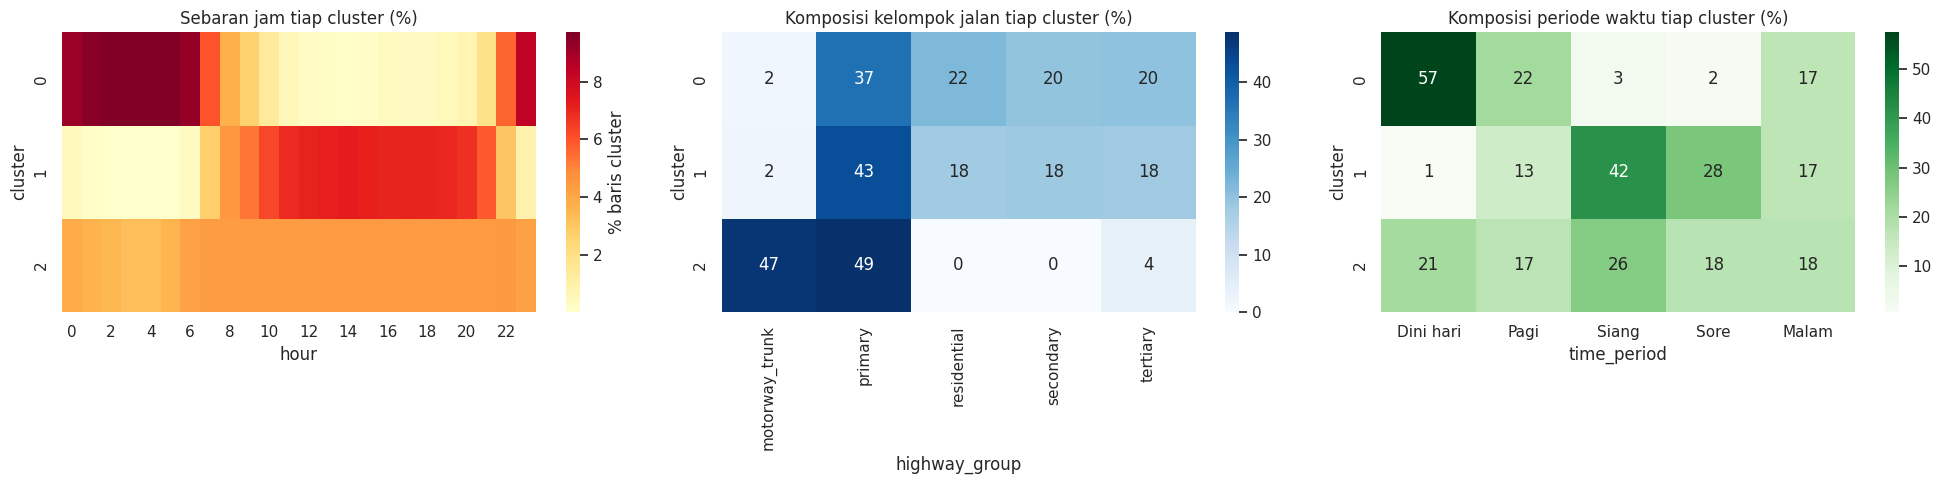

In [36]:
fig, ax = plt.subplots(1,3, figsize=(20,5))
h = pd.crosstab(fe['cluster'], fe['hour'], normalize='index')*100
sns.heatmap(h, cmap='YlOrRd', ax=ax[0], cbar_kws={'label':'% baris cluster'}); ax[0].set_title('Sebaran jam tiap cluster (%)')
tp = pd.crosstab(fe['cluster'], fe['highway_group'], normalize='index')*100
sns.heatmap(tp, annot=True, fmt='.0f', cmap='Blues', ax=ax[1]); ax[1].set_title('Komposisi kelompok jalan tiap cluster (%)')
dd = pd.crosstab(fe['cluster'], fe['time_period'], normalize='index')*100
sns.heatmap(dd, annot=True, fmt='.0f', cmap='Greens', ax=ax[2]); ax[2].set_title('Komposisi periode waktu tiap cluster (%)')
plt.tight_layout(); plt.savefig('figs/13_profil_cluster.png', dpi=110); plt.show()

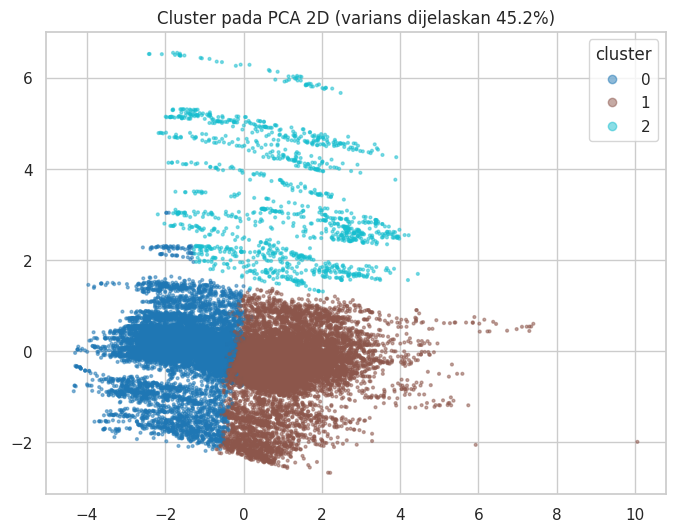

In [37]:
# Visualisasi 2D (PCA hanya untuk menggambar), pada sub-sampel
Xw = final_pipe['pre'].transform(work); Xw = np.asarray(Xw, dtype=float)
p2 = PCA(2, random_state=SEED).fit(Xw); Z = p2.transform(Xw)
sel = np.random.RandomState(SEED).choice(len(Z), min(20000, len(Z)), replace=False)
plt.figure(figsize=(8,6)); sc = plt.scatter(Z[sel,0], Z[sel,1], c=final_pipe['km'].labels_[sel], s=4, cmap='tab10', alpha=.5)
plt.legend(*sc.legend_elements(), title='cluster'); plt.title(f'Cluster pada PCA 2D (varians dijelaskan {p2.explained_variance_ratio_.sum():.1%})')
plt.savefig('figs/14_pca2d_cluster.png', dpi=110); plt.show()

Rata-rata porsi cluster dominan per sensor: 0.623 (1.0 berarti tiap sensor selalu di satu cluster)


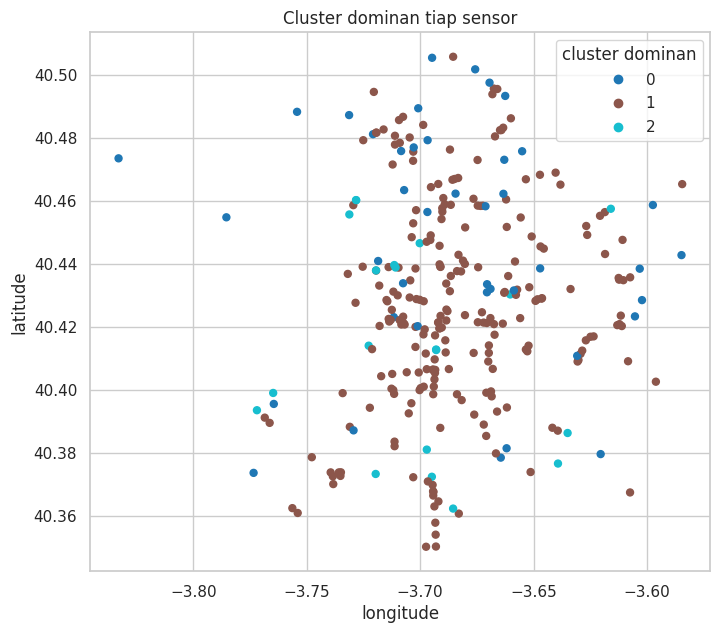

In [38]:
# Sebaran spasial: cluster dominan tiap sensor + seberapa "murni" tiap sensor
dom = fe.groupby('id')['cluster'].agg(lambda s: s.value_counts().idxmax())
loc = fe.groupby('id')[['latitude','longitude']].first().join(dom.rename('cluster_dominan'))
share = fe.groupby('id')['cluster'].value_counts(normalize=True).groupby('id').max()
print('Rata-rata porsi cluster dominan per sensor:', round(share.mean(),3), '(1.0 berarti tiap sensor selalu di satu cluster)')
plt.figure(figsize=(8,7)); sc = plt.scatter(loc['longitude'], loc['latitude'], c=loc['cluster_dominan'], cmap='tab10', s=25)
plt.legend(*sc.legend_elements(), title='cluster dominan'); plt.title('Cluster dominan tiap sensor'); plt.xlabel('longitude'); plt.ylabel('latitude')
plt.savefig('figs/15_peta_sensor.png', dpi=110); plt.show()

## 20. Ringkasan Profil Cluster

In [39]:
prof2 = fe.groupby('cluster').agg(baris=('cluster','size'), intensitas=('traffic_intensity','mean'), jam_rata2=('hour','mean'), bukan_hari_kerja=('is_non_working','mean'))
prof2['persen'] = (prof2['baris']/len(fe)*100).round(2)
prof2['periode_dominan'] = fe.groupby('cluster')['time_period'].agg(lambda s: s.astype(str).value_counts().idxmax())
prof2['jalan_dominan'] = fe.groupby('cluster')['highway_group'].agg(lambda s: s.value_counts().idxmax())
prof2.round(2)

,baris,intensitas,jam_rata2,bukan_hari_kerja,persen,periode_dominan,jalan_dominan
cluster,,,,,,,
0,1493969,194.47,7.25,0.38,40.39,Dini hari,primary
1,1972782,849.22,14.69,0.27,53.33,Siang,primary
2,232557,953.90,11.97,0.32,6.29,Siang,primary


---
# BAGIAN III. Baseline, Evaluasi Hold-out, dan Dokumentasi

## 21. Baseline dan Model Kandidat (Evaluasi Hold-out)

In [40]:
from sklearn.mixture import GaussianMixture

pre_eval = make_pre(num_A, bin_A, cat_A).fit(work)                 # fit HANYA pada sampel data latih
X_tr = np.asarray(pre_eval.transform(work), dtype=float)
test_s = fe[~is_train].sample(n=min(N_TEST, int((~is_train).sum())), random_state=SEED).reset_index(drop=True)
X_te = np.asarray(pre_eval.transform(test_s), dtype=float)
print('Latih:', X_tr.shape, '| Uji:', X_te.shape, '| periode uji:', test_s['date'].min(), 's.d.', test_s['date'].max())
print('Sensor uji yang tidak ada di sampel latih:', len(set(test_s['id']) - set(work['id'])))

RES = []
VAL = 'Hold-out temporal (uji: Jul-Okt 2023)'
def add_res(tahap, model, param, m_tr, m_te, catatan=''):
    RES.append({'tahap':tahap, 'model':model, 'parameter':param, 'validasi':VAL,
                'silhouette_latih':m_tr['silhouette'], 'db_latih':m_tr['davies_bouldin'], 'ch_latih':m_tr['calinski_harabasz'],
                'silhouette_uji':m_te['silhouette'], 'db_uji':m_te['davies_bouldin'], 'ch_uji':m_te['calinski_harabasz'], 'catatan':catatan})
    log('Hold-out: ' + tahap, model, param, m_te, 'metrik = data uji; ' + catatan)

Latih: (100000, 15) | Uji: (100000, 15) | periode uji: 2023-07-01 00:00:00 s.d. 2023-10-31 23:00:00
Sensor uji yang tidak ada di sampel latih: 0


In [41]:
# ---------- BASELINE ----------
rng = np.random.RandomState(SEED)
add_res('Baseline', f'B0 Label acak (K={K_FINAL})', f'seed={SEED}',
        evaluate(X_tr, rng.randint(0, K_FINAL, len(X_tr))), evaluate(X_te, rng.randint(0, K_FINAL, len(X_te))), 'batas bawah, tanpa struktur')
add_res('Baseline', 'B1 Aturan periode waktu', '5 kelompok: dini hari/pagi/siang/sore/malam',
        evaluate(X_tr, pd.factorize(work['time_period'].astype(str))[0]), evaluate(X_te, pd.factorize(test_s['time_period'].astype(str))[0]), 'tanpa pembelajaran')
add_res('Baseline', 'B2 Aturan kelas jalan', '5 kelompok highway_group',
        evaluate(X_tr, pd.factorize(work['highway_group'])[0]), evaluate(X_te, pd.factorize(test_s['highway_group'])[0]), 'tanpa pembelajaran')
def rule_gabungan(d):
    sepi = ((d['hour'] >= 22) | (d['hour'] <= 5)).astype(int)
    tol  = (d['highway_group'] == 'motorway_trunk').astype(int)
    return (sepi + 2*tol).values
add_res('Baseline', 'B3 Aturan gabungan (jam sepi x motorway/trunk)', '4 kelompok', evaluate(X_tr, rule_gabungan(work)), evaluate(X_te, rule_gabungan(test_s)), 'aturan sederhana berbasis temuan EDA')

In [42]:
# ---------- MODEL KANDIDAT ----------
# K-Means (K_FINAL dan K_FINAL+1)
for k in [K_FINAL, K_FINAL+1]:
    km = KMeans(k, n_init=10, random_state=SEED).fit(X_tr)
    add_res('Kandidat', f'K-Means (K={k})', 'n_init=10', evaluate(X_tr, km.labels_), evaluate(X_te, km.predict(X_te)), f'inertia latih={km.inertia_:.0f}')
    if k == K_FINAL: km_main = km

# Gaussian Mixture (klasik, cluster boleh berbentuk elips; kovarians diagonal)
gmm = GaussianMixture(K_FINAL, covariance_type='diag', n_init=3, random_state=SEED).fit(X_tr)
add_res('Kandidat', f'Gaussian Mixture (K={K_FINAL})', 'covariance=diag, n_init=3', evaluate(X_tr, gmm.predict(X_tr)), evaluate(X_te, gmm.predict(X_te)), 'cluster lunak diubah menjadi keras (argmax)')

# Hierarchical Ward dilatih pada sub-sampel; data latih dan data uji diberi cluster dengan centroid terdekat (protokol sama)
idx_h2 = np.random.RandomState(SEED).choice(len(X_tr), min(HIER_N, len(X_tr)), replace=False); Xh2 = X_tr[idx_h2]
ag2 = AgglomerativeClustering(n_clusters=K_FINAL, linkage='ward').fit(Xh2)
cent = np.vstack([Xh2[ag2.labels_ == c].mean(axis=0) for c in range(K_FINAL)])
assign = lambda Z: np.argmin(((Z[:, None, :] - cent[None, :, :])**2).sum(axis=2), axis=1)
lab_tr_ward, lab_te_ward = assign(X_tr), assign(X_te)
add_res('Kandidat', f'Agglomerative Ward (K={K_FINAL})', f'dilatih pada {len(Xh2)} baris; centroid terdekat', evaluate(X_tr, lab_tr_ward), evaluate(X_te, lab_te_ward), 'latih dan uji memakai protokol penugasan yang sama')

res_df = pd.DataFrame(RES)
res_df['selisih_silhouette (uji-latih)'] = res_df['silhouette_uji'] - res_df['silhouette_latih']
res_df.round(4)

,tahap,model,parameter,validasi,silhouette_latih,db_latih,ch_latih,silhouette_uji,db_uji,ch_uji,catatan,selisih_silhouette (uji-latih)
0,Baseline,B0 Label acak (K=3),seed=42,Hold-out temporal (uji: Jul-Okt 2023),-0.0019,394.6531,0.6226,-0.0011,295.1667,2.0433,"batas bawah, tanpa struktur",0.0008
1,Baseline,B1 Aturan periode waktu,5 kelompok: dini hari/pagi/siang/sore/malam,Hold-out temporal (uji: Jul-Okt 2023),0.0847,2.7346,10115.2575,0.0826,2.7791,9769.1247,tanpa pembelajaran,-0.0020
2,Baseline,B2 Aturan kelas jalan,5 kelompok highway_group,Hold-out temporal (uji: Jul-Okt 2023),0.0801,3.0314,5395.3871,0.0827,2.9935,5515.2487,tanpa pembelajaran,0.0026
3,Baseline,B3 Aturan gabungan (jam sepi x motorway/trunk),4 kelompok,Hold-out temporal (uji: Jul-Okt 2023),0.1528,2.0772,9143.0682,0.1460,2.1137,8615.6341,aturan sederhana berbasis temuan EDA,-0.0068
4,Kandidat,K-Means (K=3),n_init=10,Hold-out temporal (uji: Jul-Okt 2023),0.2175,1.6023,20845.2000,0.2055,1.6502,19741.2683,inertia latih=645103,-0.0120
5,Kandidat,K-Means (K=4),n_init=10,Hold-out temporal (uji: Jul-Okt 2023),0.1759,1.8380,18418.5756,0.1714,1.8428,17708.2918,inertia latih=588735,-0.0045
6,Kandidat,Gaussian Mixture (K=3),"covariance=diag, n_init=3",Hold-out temporal (uji: Jul-Okt 2023),0.0833,2.6712,11814.9299,0.0838,2.6924,11328.6006,cluster lunak diubah menjadi keras (argmax),0.0005
7,Kandidat,Agglomerative Ward (K=3),dilatih pada 8000 baris; centroid terdekat,Hold-out temporal (uji: Jul-Okt 2023),0.2152,1.6115,20581.4910,0.2040,1.6592,19501.3068,latih dan uji memakai protokol penugasan yang ...,-0.0112


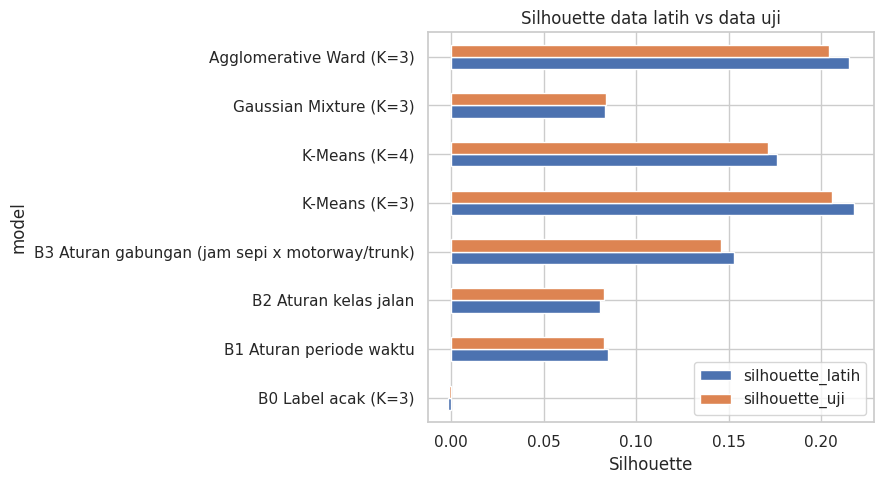

In [43]:
# DBSCAN tidak dibawa ke hold-out: pada bagian 16 tidak menemukan struktur kepadatan yang jelas dan tidak memiliki predict.
# Grafik perbandingan Silhouette latih vs uji
pl = res_df.set_index('model')[['silhouette_latih','silhouette_uji']]
ax = pl.plot(kind='barh', figsize=(9, 5)); ax.set_xlabel('Silhouette'); ax.set_title('Silhouette data latih vs data uji')
plt.tight_layout(); plt.savefig('figs/20_baseline_vs_kandidat.png', dpi=110); plt.show()

In [44]:
# Proporsi cluster tiap model kandidat pada data latih dan data uji
sz = lambda lab: pd.Series(lab).value_counts(normalize=True).sort_index().round(3)
pd.DataFrame({f'K-Means K={K_FINAL} latih': sz(km_main.labels_), f'K-Means K={K_FINAL} uji': sz(km_main.predict(X_te)),
              'GMM latih': sz(gmm.predict(X_tr)), 'GMM uji': sz(gmm.predict(X_te)),
              'Ward latih': sz(lab_tr_ward), 'Ward uji': sz(lab_te_ward)})

,K-Means K=3 latih,K-Means K=3 uji,GMM latih,GMM uji,Ward latih,Ward uji
0,0.403,0.412,0.227,0.235,0.539,0.531
1,0.535,0.526,0.367,0.359,0.399,0.408
2,0.062,0.062,0.406,0.406,0.062,0.062


## 22. Konsistensi Hold-out, Kestabilan Antar-Periode, dan Pergeseran Distribusi

In [45]:
# (a) Konsistensi: model yang dilatih pada data latih vs model yang dilatih ulang pada data uji
lab_pred = km_main.predict(X_te)
km_te = KMeans(K_FINAL, n_init=10, random_state=SEED).fit(X_te)      # HANYA untuk uji konsistensi, bukan untuk memilih model
ari_refit = adjusted_rand_score(lab_pred, km_te.labels_)
print('ARI antara label model latih dan model yang dilatih ulang pada data uji:', round(ari_refit, 3))

# (b) Kestabilan antar-periode: latih K-Means pada tiga periode latih berbeda, bandingkan label pada data uji yang sama
periods = {'P1: Jun-Okt 2022':('2022-06-01','2022-11-01'), 'P2: Nov 2022-Feb 2023':('2022-11-01','2023-03-01'), 'P3: Mar-Jun 2023':('2023-03-01','2023-07-01')}
labs = {}
for nm, (a, b) in periods.items():
    idx = np.flatnonzero(((fe['date'] >= a) & (fe['date'] < b)).values)
    idx = np.random.RandomState(SEED).choice(idx, min(40_000, len(idx)), replace=False)
    Xp = np.asarray(pre_eval.transform(fe.iloc[idx]), dtype=float)       # scaler tetap dari data latih
    labs[nm] = KMeans(K_FINAL, n_init=10, random_state=SEED).fit(Xp).predict(X_te)
names = list(labs)
ari_per = pd.DataFrame(index=names, columns=names, dtype=float)
for p in names:
    for q in names: ari_per.loc[p, q] = adjusted_rand_score(labs[p], labs[q])
print('ARI antar model yang dilatih pada periode berbeda (dinilai pada data uji yang sama):')
ari_per.round(3)

ARI antara label model latih dan model yang dilatih ulang pada data uji: 0.958
ARI antar model yang dilatih pada periode berbeda (dinilai pada data uji yang sama):


,P1: Jun-Okt 2022,P2: Nov 2022-Feb 2023,P3: Mar-Jun 2023
P1: Jun-Okt 2022,1.000,0.878,0.930
P2: Nov 2022-Feb 2023,0.878,1.000,0.854
P3: Mar-Jun 2023,0.930,0.854,1.000


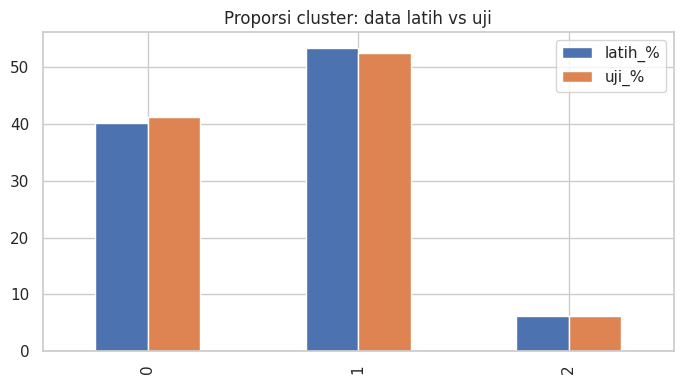

,latih_%,uji_%,selisih
0,40.27,41.24,0.97
1,53.49,52.58,-0.91
2,6.25,6.18,-0.07


In [46]:
# (c) Pergeseran distribusi cluster antara data latih dan data uji (label dari model latih)
shift = pd.DataFrame({'latih_%': pd.Series(km_main.labels_).value_counts(normalize=True).sort_index()*100,
                      'uji_%':   pd.Series(lab_pred).value_counts(normalize=True).sort_index()*100}).round(2)
shift['selisih'] = (shift['uji_%'] - shift['latih_%']).round(2)
log('Konsistensi', 'K-Means', f'K={K_FINAL}', {'silhouette':np.nan,'davies_bouldin':np.nan,'calinski_harabasz':np.nan}, f'ARI refit uji={ari_refit:.3f}; ARI antar-periode min={np.nanmin(ari_per.values[np.triu_indices(len(names),1)]):.3f}')
shift.plot(kind='bar', y=['latih_%','uji_%'], figsize=(7,4), title='Proporsi cluster: data latih vs uji'); plt.tight_layout()
plt.savefig('figs/21_pergeseran_cluster.png', dpi=110); plt.show()
shift

## 23. Tabel Hasil Eksperimen Awal

In [47]:
tabel = res_df[['tahap','model','parameter','validasi','silhouette_latih','silhouette_uji','db_latih','db_uji','ch_latih','ch_uji','catatan']].copy()
extra = pd.DataFrame([
  {'tahap':'Validasi','model':f'K-Means K={K_FINAL}','parameter':'refit pada data uji','validasi':'Konsistensi hold-out (ARI)','catatan':f'ARI = {ari_refit:.3f}'},
  {'tahap':'Validasi','model':f'K-Means K={K_FINAL}','parameter':'3 periode latih berbeda','validasi':'Kestabilan antar-periode (ARI)','catatan':'ARI min/maks = %.3f / %.3f' % (np.nanmin(ari_per.values[np.triu_indices(len(names),1)]), np.nanmax(ari_per.values[np.triu_indices(len(names),1)]))}])
tabel = pd.concat([tabel, extra], ignore_index=True)
tabel.to_csv('hasil_eksperimen_awal.csv', index=False)
tabel.round(4)

,tahap,model,parameter,validasi,silhouette_latih,silhouette_uji,db_latih,db_uji,ch_latih,ch_uji,catatan
0,Baseline,B0 Label acak (K=3),seed=42,Hold-out temporal (uji: Jul-Okt 2023),-0.0019,-0.0011,394.6531,295.1667,0.6226,2.0433,"batas bawah, tanpa struktur"
1,Baseline,B1 Aturan periode waktu,5 kelompok: dini hari/pagi/siang/sore/malam,Hold-out temporal (uji: Jul-Okt 2023),0.0847,0.0826,2.7346,2.7791,10115.2575,9769.1247,tanpa pembelajaran
2,Baseline,B2 Aturan kelas jalan,5 kelompok highway_group,Hold-out temporal (uji: Jul-Okt 2023),0.0801,0.0827,3.0314,2.9935,5395.3871,5515.2487,tanpa pembelajaran
3,Baseline,B3 Aturan gabungan (jam sepi x motorway/trunk),4 kelompok,Hold-out temporal (uji: Jul-Okt 2023),0.1528,0.1460,2.0772,2.1137,9143.0682,8615.6341,aturan sederhana berbasis temuan EDA
4,Kandidat,K-Means (K=3),n_init=10,Hold-out temporal (uji: Jul-Okt 2023),0.2175,0.2055,1.6023,1.6502,20845.2000,19741.2683,inertia latih=645103
5,Kandidat,K-Means (K=4),n_init=10,Hold-out temporal (uji: Jul-Okt 2023),0.1759,0.1714,1.8380,1.8428,18418.5756,17708.2918,inertia latih=588735
6,Kandidat,Gaussian Mixture (K=3),"covariance=diag, n_init=3",Hold-out temporal (uji: Jul-Okt 2023),0.0833,0.0838,2.6712,2.6924,11814.9299,11328.6006,cluster lunak diubah menjadi keras (argmax)
7,Kandidat,Agglomerative Ward (K=3),dilatih pada 8000 baris; centroid terdekat,Hold-out temporal (uji: Jul-Okt 2023),0.2152,0.2040,1.6115,1.6592,20581.4910,19501.3068,latih dan uji memakai protokol penugasan yang ...
8,Validasi,K-Means K=3,refit pada data uji,Konsistensi hold-out (ARI),NaN,NaN,NaN,NaN,NaN,NaN,ARI = 0.958
9,Validasi,K-Means K=3,3 periode latih berbeda,Kestabilan antar-periode (ARI),NaN,NaN,NaN,NaN,NaN,NaN,ARI min/maks = 0.854 / 0.930


## 24. Uji Dampak Fitur (Ablasi)

In [48]:
# K-Means (K_FINAL) tanpa salah satu fitur/kelompok fitur, dibandingkan dengan model penuh (data latih)
def run_km(num, binf, cat):
    pre = make_pre(num, binf, cat).fit(work)
    Z = np.asarray(pre.transform(work), dtype=float)
    return Z, KMeans(K_FINAL, n_init=5, random_state=SEED).fit(Z).labels_

Z_full, lab_full = run_km(num_A, bin_A, cat_A)
varian = [('Model penuh (Set A)', num_A, bin_A, cat_A),
          ('tanpa intensity_per_lane', [f for f in num_A if f != 'intensity_per_lane'], bin_A, cat_A),
          ('tanpa rel_intensity', [f for f in num_A if f != 'rel_intensity'], bin_A, cat_A),
          ('tanpa log_intensity', [f for f in num_A if f != 'log_intensity'], bin_A, cat_A),
          ('tanpa hour_sin dan hour_cos', [f for f in num_A if f not in ('hour_sin','hour_cos')], bin_A, cat_A),
          ('tanpa is_non_working', num_A, [f for f in bin_A if f != 'is_non_working'], cat_A),
          ('tanpa highway_group', num_A, bin_A, [])]
rows = []
for nama, nu, bi, ca in varian:
    Zv, lab_v = run_km(nu, bi, ca)
    m_full, m_own = evaluate(Z_full, lab_v), evaluate(Zv, lab_v)
    rows.append({'varian': nama, 'jumlah_kolom': Zv.shape[1], 'ARI_vs_penuh': adjusted_rand_score(lab_full, lab_v),
                 'silhouette_ruang_penuh': m_full['silhouette'], 'db_ruang_penuh': m_full['davies_bouldin'], 'silhouette_ruang_sendiri': m_own['silhouette']})
    log('Ablasi fitur', 'KMeans', f'K={K_FINAL}; {nama}', m_full, f"ARI vs penuh={rows[-1]['ARI_vs_penuh']:.3f}")
abl = pd.DataFrame(rows).round(4); abl.to_csv('ablasi_fitur.csv', index=False); abl

,varian,jumlah_kolom,ARI_vs_penuh,silhouette_ruang_penuh,db_ruang_penuh,silhouette_ruang_sendiri
0,Model penuh (Set A),15,1.0000,0.2175,1.6023,0.2175
1,tanpa intensity_per_lane,14,0.9133,0.2165,1.6027,0.2239
2,tanpa rel_intensity,14,0.8101,0.2082,1.6503,0.1824
3,tanpa log_intensity,14,0.8207,0.2121,1.6298,0.2073
4,tanpa hour_sin dan hour_cos,13,0.6898,0.1991,1.6824,0.2139
5,tanpa is_non_working,14,0.9905,0.2175,1.6016,0.2238
6,tanpa highway_group,10,0.8367,0.2040,1.8754,0.2259


## 25. Catatan Eksperimen dan Parameter

In [49]:
log_df = pd.DataFrame(LOG).round(4)
log_df.to_csv('data_experiment_log.csv', index=False)
print('Seed:', SEED, '| CUTOFF:', CUTOFF.date(), '| N latih:', len(work), '| N uji:', len(test_s), '| K_FINAL:', K_FINAL)
print('Versi: scikit-learn', sklearn.__version__, '| pandas', pd.__version__, '| numpy', np.__version__)
log_df

Seed: 42 | CUTOFF: 2023-07-01 | N latih: 100000 | N uji: 100000 | K_FINAL: 3
Versi: scikit-learn 1.6.1 | pandas 2.2.3 | numpy 2.4.6


,eksperimen,algoritma,parameter,seed,silhouette,davies_bouldin,calinski_harabasz,catatan
0,Sweep K (Fitur Set A),KMeans,"k=2, n_init=5",42,0.2097,1.7627,26887.2648,
1,Sweep K (Fitur Set A),KMeans,"k=3, n_init=5",42,0.2175,1.6023,20845.2000,
2,Sweep K (Fitur Set A),KMeans,"k=4, n_init=5",42,0.1759,1.8380,18418.5756,
3,Sweep K (Fitur Set A),KMeans,"k=5, n_init=5",42,0.1782,1.6864,17243.5655,
4,Sweep K (Fitur Set A),KMeans,"k=6, n_init=5",42,0.1735,1.6238,16046.9748,
5,Sweep K (Fitur Set A),KMeans,"k=7, n_init=5",42,0.1478,1.7377,15057.7291,
6,Sweep K (Fitur Set A),KMeans,"k=8, n_init=5",42,0.1455,1.6906,14247.0095,
7,Sweep K (Fitur Set A),KMeans,"k=9, n_init=5",42,0.1406,1.6239,13556.6916,
8,Sweep K (Fitur Set A),KMeans,"k=10, n_init=5",42,0.1462,1.5898,12938.2238,
9,Fitur Set A vs B,KMeans,K=3; A (tanpa cuaca) di ruang A,42,0.2175,1.6023,20845.2000,"ARI(A,B)=0.859"


## 26. Instruksi Reproduksi
**Lingkungan:** Google Colab; pandas, numpy, scikit-learn, matplotlib, seaborn (versi dicetak pada bagian 25). RAM sekitar 12 GB atau lebih untuk data penuh (3,7 juta baris).

1. Unduh data dari Mendeley Data (https://data.mendeley.com/datasets/697ht4f65b, DOI 10.17632/697ht4f65b.4): folder **Subset dataset**, file `MTD_complete_data.csv` (sekitar 790 MB). Bukan folder Complete dataset (sekitar 10 GB).
2. Unggah file ke Google Drive, lalu sesuaikan `PATH` pada sel Setup dan Load Data.
3. Jika RAM tidak cukup, buat sampel 1% (hasil akan berbeda dari data penuh):
```python
import pandas as pd
chunks = pd.read_csv('MTD_complete_data.csv', chunksize=500_000)
pd.concat(c.sample(frac=0.01, random_state=42) for c in chunks).to_csv('sample.csv', index=False)
```
4. Jalankan seluruh sel berurutan (Runtime, Run all). Lama proses bergantung pada kapasitas sesi Colab.
5. Keluaran: `figs/*.png`, `data/*.csv`, `hasil_eksperimen_awal.csv`, `ablasi_fitur.csv`, `data_experiment_log.csv`.

**Parameter tetap:** `SEED = 42`, `CUTOFF = 2023-07-01`, `N_MODEL = N_TEST = 100.000`.
**Lisensi data:** Creative Commons Attribution 4.0 (CC BY 4.0). Data tidak disertakan di repository karena ukurannya (sekitar 790 MB) melebihi batas GitHub 100 MB.

## 27. Rencana Pasca-UTS hingga UAS
| Tahap | Pekerjaan | Dasar dari temuan awal | Luaran |
|---|---|---|---|
| 1. Perkuat validasi | Rolling-origin (beberapa periode uji), lebih banyak seed, n_init lebih besar | Hold-out hanya satu pembagian waktu; ARI antar-seed belum selalu 1 (bagian 18, 22) | Tabel kestabilan |
| 2. Formulasi alternatif | Clustering profil per sensor (rata-rata intensitas per jam dan jenis hari); uji K lain | Silhouette rendah, cluster sensor-jam saling tumpang tindih (bagian 14, 23) | Perbandingan dua formulasi |
| 3. Perkaya fitur | Fitur tetangga spasial, perubahan dari jam sebelumnya, kalender libur | Hasil ablasi (bagian 24) dan aturan sederhana B3 menjelaskan sebagian besar struktur (bagian 23) | Tabel ablasi fitur tambahan |
| 4. Periksa kandidat lemah | Profil dan ukuran cluster GMM dan DBSCAN; tuning ringan | GMM dan DBSCAN kurang baik pada metrik (bagian 16, 21) | Catatan penyebab kelemahan |
| 5. Pipeline final | Simpan pipeline, README, uji jalan ulang dari awal | Syarat reproduksi (bagian 26) | Repository reprodusibel |
| 6. Laporan UAS | Perbarui hasil, keterbatasan, dan rekomendasi | Seluruh temuan | Laporan dan notebook UAS |

## 28. Ringkasan Hasil

In [50]:
base_row = res_df[res_df['tahap'] == 'Baseline'].sort_values('silhouette_uji').iloc[-1]
km_row = res_df[res_df['model'] == f'K-Means (K={K_FINAL})'].iloc[0]
pd.DataFrame({'K_FINAL': [K_FINAL],
  'silhouette_latih': [km_row['silhouette_latih']], 'silhouette_uji': [km_row['silhouette_uji']],
  'db_latih': [km_row['db_latih']], 'db_uji': [km_row['db_uji']],
  'baseline_terbaik': [base_row['model']], 'silhouette_uji_baseline_terbaik': [base_row['silhouette_uji']],
  'ARI_refit_uji': [ari_refit], 'ARI_antar_periode_min': [np.nanmin(ari_per.values[np.triu_indices(len(names),1)])],
  'ARI_antar_seed_rata2': [np.mean(aris)]}).round(4).T

,0
K_FINAL,3
silhouette_latih,0.2175
silhouette_uji,0.2055
db_latih,1.6023
db_uji,1.6502
baseline_terbaik,B3 Aturan gabungan (jam sepi x motorway/trunk)
silhouette_uji_baseline_terbaik,0.146
ARI_refit_uji,0.9584
ARI_antar_periode_min,0.8538
ARI_antar_seed_rata2,0.9425


## 29. Referensi
1. Gómez, I., & Ilarri, S. (2026). Enriched Traffic Datasets for Madrid (Version 4) [Data set]. Mendeley Data. https://doi.org/10.17632/697ht4f65b.4
2. Gómez, I., & Ilarri, S. (2025). Advanced prediction of traffic at different temporal scales using heterogeneous data sources. IEEE Open Journal of Intelligent Transportation Systems, 6, 1539-1550. https://doi.org/10.1109/OJITS.2025.3637305
3. scikit-learn developers. (2025). scikit-learn (Version 1.6.1) [Computer software]. https://github.com/scikit-learn/scikit-learn